# AI-Powered Financial Transaction Risk Detection System

## Project Overview

Financial fraud detection is a challenging machine learning problem because fraudulent transactions represent only a small proportion of total transactions. A useful detection system must identify suspicious transactions while controlling false alarms.

This project develops a binary classification system to identify potentially fraudulent financial transactions using the BankSim synthetic transaction dataset.

### Objectives
- Explore transaction patterns and investigate factors associated with fraud.
- Perform data preprocessing and feature engineering.
- Compare Logistic Regression, Decision Tree, and Linear SVM models.
- Handle class imbalance and select a decision threshold based on validation performance.
- Evaluate the final model using a chronological train-validation-test split.
- Interpret model predictions and prepare the trained model for deployment.

### Dataset
- **Dataset:** BankSim synthetic transaction dataset
- **Target variable:** `fraud` — 0 represents a legitimate transaction and 1 represents a fraudulent transaction.
- **Original size:** 594,643 transactions and 10 columns.
- **Class imbalance:** Approximately 1.21% of transactions are labelled fraudulent.

### Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

### Workflow
Exploratory Data Analysis → Feature Engineering → Model Training → Model Comparison → Threshold Selection → Final Evaluation → Explainability → Deployment Preparation.

**Note:** BankSim is a synthetic dataset. Results on this dataset do not establish real-world banking performance.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math as m
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv("../Data/bs140513_032310.csv/bs140513_032310.csv")

In [3]:
df

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0
...,...,...,...,...,...,...,...,...,...,...
594638,179,'C1753498738','3','F','28007','M1823072687','28007','es_transportation',20.53,0
594639,179,'C650108285','4','F','28007','M1823072687','28007','es_transportation',50.73,0
594640,179,'C123623130','2','F','28007','M349281107','28007','es_fashion',22.44,0
594641,179,'C1499363341','5','M','28007','M1823072687','28007','es_transportation',14.46,0


## BankSim Dataset — Variable Descriptions

| Variable | Description |
|---|---|
| `step` | Represents the time granularity of the simulation. Each step corresponds to one day of simulated commercial activity. |
| `customer` | An identifier for the customer involved in the transaction. It helps identify transactions belonging to the same customer. |
| `age` | Represents the customer's age category: `'0'` (18 years or younger), `'1'` (19–25), `'2'` (26–35), `'3'` (36–45), `'4'` (46–55), `'5'` (56–65), `'6'` (over 65), and `'U'` (unknown age). |
| `gender` | Represents the customer's gender category. The documented categories are `E` (Enterprise), `F` (Female), `M` (Male), and `U` (Unknown). |
| `zipcodeOri` | Represents the ZIP code associated with the customer's origin. |
| `merchant` | An identifier for the merchant involved in the transaction. |
| `zipMerchant` | Represents the ZIP code associated with the merchant's location. |
| `category` | Represents the merchant category associated with the purchased goods or services, such as transportation, food, restaurants, or fashion. |
| `amount` | Represents the monetary value of the transaction, measured in euros (€). |
| `fraud` | The binary target variable indicating whether a transaction is fraudulent: `0` = legitimate transaction and `1` = fraudulent transaction. |

### Key Observations

- Each row represents one transaction.
- A customer may have multiple transactions with different merchants.
- `customer` and `merchant` are identifiers, not numerical measurements.
- `age`, `gender`, and `category` are categorical features.
- `amount` represents the transaction value, while `fraud` is the target variable for our prediction task.

**Note:** The dataset is synthetic and simulates financial transactions. We will inspect the actual values and distributions of each column before deciding on data cleaning, encoding, or feature engineering.

In [4]:
df.columns

Index(['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant',
       'zipMerchant', 'category', 'amount', 'fraud'],
      dtype='object')

In [5]:
df.shape

(594643, 10)

In [6]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [7]:
df.tail()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
594638,179,'C1753498738','3','F','28007','M1823072687','28007','es_transportation',20.53,0
594639,179,'C650108285','4','F','28007','M1823072687','28007','es_transportation',50.73,0
594640,179,'C123623130','2','F','28007','M349281107','28007','es_fashion',22.44,0
594641,179,'C1499363341','5','M','28007','M1823072687','28007','es_transportation',14.46,0
594642,179,'C616528518','4','F','28007','M1823072687','28007','es_transportation',26.93,0


In [8]:
df.sample(10)

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
337226,109,'C1305161735','6','M','28007','M348934600','28007','es_transportation',30.69,0
260765,87,'C1108226372','2','M','28007','M1823072687','28007','es_transportation',24.76,0
52466,20,'C1977634536','4','F','28007','M1823072687','28007','es_transportation',32.25,0
146374,51,'C470079617','5','F','28007','M348934600','28007','es_transportation',52.22,0
204202,70,'C644663928','2','M','28007','M348934600','28007','es_transportation',2.22,0
221606,75,'C1762043633','4','F','28007','M348934600','28007','es_transportation',42.56,0
478560,148,'C228882909','2','M','28007','M349281107','28007','es_fashion',61.43,0
69323,26,'C1776310825','4','M','28007','M1823072687','28007','es_transportation',3.02,0
411328,130,'C619451848','2','F','28007','M85975013','28007','es_food',9.94,0
225933,76,'C200459252','1','M','28007','M348934600','28007','es_transportation',21.61,0


In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB


In [12]:
for col in df.columns:
    print(f"{col} : {df[col].unique()} Unique values\n")

step : [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179] Unique values

customer : ["'C1093826151'" "'C352968107'" "'C2054744914'" ... "'C1014783484'"
 "'C849065220'" "'C1809646275'"] Unique values

age : ["'4'" "'2'" "'3'" "'5'" "'1'" "'6'" "'U'" "'0'"] Unique values

gender : ["'M'" "'F'" "'E'" "'U'"] Unique values


In [13]:
df.dtypes

step             int64
customer        object
age             object
gender          object
zipcodeOri      object
merchant        object
zipMerchant     object
category        object
amount         float64
fraud            int64
dtype: object

In [14]:

df.duplicated().sum()

np.int64(0)

In [15]:
for col in df.columns:
    print(col, ":", df[col].nunique())

step : 180
customer : 4112
age : 8
gender : 4
zipcodeOri : 1
merchant : 50
zipMerchant : 1
category : 15
amount : 23767
fraud : 2


In [16]:
df[['step', 'amount']].describe()

,step,amount
count,594643.000000,594643.000000
mean,94.986827,37.890135
std,51.053632,111.402831
min,0.000000,0.000000
25%,52.000000,13.740000
50%,97.000000,26.900000
75%,139.000000,42.540000
max,179.000000,8329.960000


In [17]:
print("Zero amounts:", (df['amount'] == 0).sum())
print("Negative amounts:", (df['amount'] < 0).sum())
print("Positive amounts:", (df['amount'] > 0).sum())

Zero amounts: 52
Negative amounts: 0
Positive amounts: 594591


In [18]:
df['fraud'].unique()

array([0, 1])

In [19]:
df['fraud'].value_counts(dropna=False)

fraud
0    587443
1      7200
Name: count, dtype: int64

In [20]:
(df['amount'] < 0).sum(), (df['amount'] == 0).sum(), (df['amount'].isna()).sum()

(np.int64(0), np.int64(52), np.int64(0))

In [21]:
df[df['amount'] == 0].head(52)

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
40502,15,'C1918953803','2','F','28007','M348934600','28007','es_transportation',0.0,0
46361,17,'C782199851','2','F','28007','M348934600','28007','es_transportation',0.0,0
48560,18,'C92282564','3','F','28007','M348934600','28007','es_transportation',0.0,0
64613,24,'C612357573','6','M','28007','M348934600','28007','es_transportation',0.0,0
84320,31,'C1299474405','4','F','28007','M348934600','28007','es_transportation',0.0,0
87713,32,'C1814870538','3','M','28007','M1823072687','28007','es_transportation',0.0,0
88889,32,'C1189224644','2','M','28007','M1823072687','28007','es_transportation',0.0,0
89155,32,'C1598762673','3','M','28007','M1823072687','28007','es_transportation',0.0,0
127028,45,'C876944738','2','F','28007','M1823072687','28007','es_transportation',0.0,0
133555,47,'C73919470','3','F','28007','M348934600','28007','es_transportation',0.0,0


In [22]:
df.loc[df['amount']==0, 'fraud'].value_counts()

fraud
0    52
Name: count, dtype: int64

In [23]:
df['customer'].duplicated().sum()

np.int64(590531)

In [24]:
(df.astype(str).apply(lambda col: col.str.strip().eq('').sum()))

step           0
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
amount         0
fraud          0
dtype: int64

In [25]:
df['step'].min(), df['step'].max(), df['step'].isna().sum()

(np.int64(0), np.int64(179), np.int64(0))

In [26]:
df['fraud'].value_counts(dropna=False)

fraud
0    587443
1      7200
Name: count, dtype: int64

In [27]:
df['gender'].unique()

array(["'M'", "'F'", "'E'", "'U'"], dtype=object)

In [28]:
df['age'].unique()

array(["'4'", "'2'", "'3'", "'5'", "'1'", "'6'", "'U'", "'0'"],
      dtype=object)

In [29]:
df['category'].unique()

array(["'es_transportation'", "'es_health'", "'es_otherservices'",
       "'es_food'", "'es_hotelservices'", "'es_barsandrestaurants'",
       "'es_tech'", "'es_sportsandtoys'", "'es_wellnessandbeauty'",
       "'es_hyper'", "'es_fashion'", "'es_home'", "'es_contents'",
       "'es_travel'", "'es_leisure'"], dtype=object)

In [30]:
df['merchant'].unique()

array(["'M348934600'", "'M1823072687'", "'M50039827'", "'M1888755466'",
       "'M1053599405'", "'M85975013'", "'M480139044'", "'M692898500'",
       "'M348875670'", "'M151143676'", "'M840466850'", "'M1741626453'",
       "'M1535107174'", "'M855959430'", "'M349281107'", "'M209847108'",
       "'M2122776122'", "'M1873032707'", "'M2011752106'", "'M857378720'",
       "'M1198415165'", "'M1748431652'", "'M980657600'", "'M1352454843'",
       "'M117188757'", "'M547558035'", "'M17379832'", "'M1649169323'",
       "'M1946091778'", "'M97925176'", "'M923029380'", "'M1353266412'",
       "'M1842530320'", "'M677738360'", "'M1313686961'", "'M732195782'",
       "'M1600850729'", "'M1872033263'", "'M3697346'", "'M495352832'",
       "'M1400236507'", "'M1294758098'", "'M1913465890'", "'M45060432'",
       "'M78078399'", "'M2080407379'", "'M1788569036'", "'M1416436880'",
       "'M933210764'", "'M1726401631'"], dtype=object)

In [31]:
df['zipcodeOri'].unique()

array(["'28007'"], dtype=object)

In [32]:
df['zipMerchant'].unique()

array(["'28007'"], dtype=object)

## Dataset Audit Summary

### 1. Dataset Overview
- **Dataset:** BankSim
- **Rows:** 594,643 transactions
- **Columns:** 10
- **Target variable:** `fraud`
- **Problem type:** Binary classification

### 2. Data Quality Checks
- **Missing values:** No missing values found.
- **Exact duplicate rows:** 0
- **Blank-string values:** None found.
- **Negative transaction amounts:** 0
- **Zero transaction amounts:** 52
- **Zero-amount transaction labels:** All 52 are legitimate transactions (`fraud = 0`).
- **Step range:** 0–179, with no missing values.

### 3. Unique Values and Column Checks
- `step`: 180 unique values
- `customer`: 4,112 unique customer IDs
- `age`: 8 categories
- `gender`: 4 categories
- `zipcodeOri`: 1 unique value (`'28007'`)
- `merchant`: 50 unique merchants
- `zipMerchant`: 1 unique value (`'28007'`)
- `category`: 15 transaction categories
- `amount`: 23,767 unique values
- `fraud`: 2 classes (`0` and `1`)

### 4. Target Variable
- Legitimate transactions (`0`): 587,443
- Fraudulent transactions (`1`): 7,200
- Fraudulent transactions represent approximately **1.21%** of the dataset.
- The target classes are highly imbalanced.

### 5. Audit Decisions
- No rows or columns have been deleted.
- Zero-amount transactions are retained pending further investigation.
- `zipcodeOri` and `zipMerchant` are constant columns and are candidates for removal during preprocessing.
- `age` and `gender` contain documented categorical labels, including `'U'` for unknown.
- BankSim is a synthetic dataset; results should be interpreted accordingly.

### 6. Conclusion
The initial dataset audit found no missing values, exact duplicate rows, blank strings, or negative transaction amounts. However, zero-amount transactions require consideration, two geographic columns are constant, and the target variable is highly imbalanced. These findings will guide the subsequent exploratory data analysis and preprocessing stages.

In [33]:
#UNIVEARIATE ANALYSIS

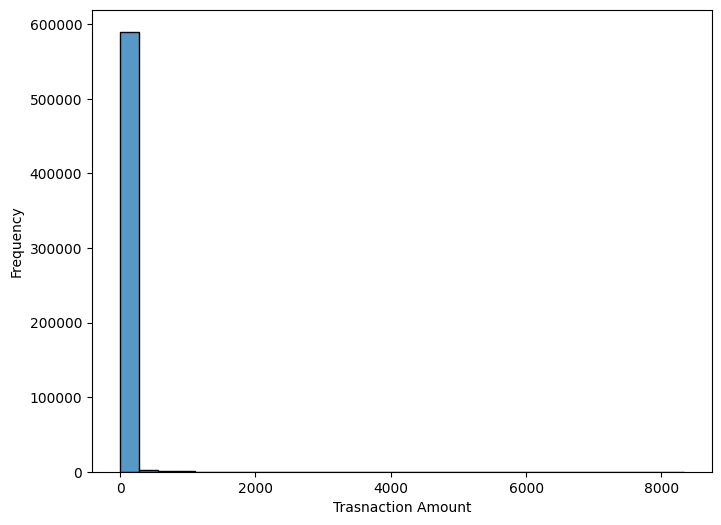

In [34]:
plt.figure(figsize=(8, 6))
sns.histplot(x="amount", data=df, bins=30)
plt.xlabel("Trasnaction Amount")
plt.ylabel("Frequency")
plt.show()

he transaction amount distribution is highly right-skewed, with most transactions having relatively small amounts.

A few transactions have very large amounts, creating a long tail on the right.

Potential outliers will be investigated using the IQR method.

In [35]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = 1.5 - 1.5*IQR
upper_bound = 1.5 + 1.5*IQR

print("IQR: ", IQR)
print("Lower_Bound: ", lower_bound)
print("Upper_Bound: ", upper_bound)

IQR:  28.799999999999997
Lower_Bound:  -41.699999999999996
Upper_Bound:  44.699999999999996


In [36]:
df[df['amount'] > upper_bound].value_counts().sum()

np.int64(133123)

In [37]:
percentage = (133123/594643)*100
print("Percentage: ", percentage)

Percentage:  22.38704567278182


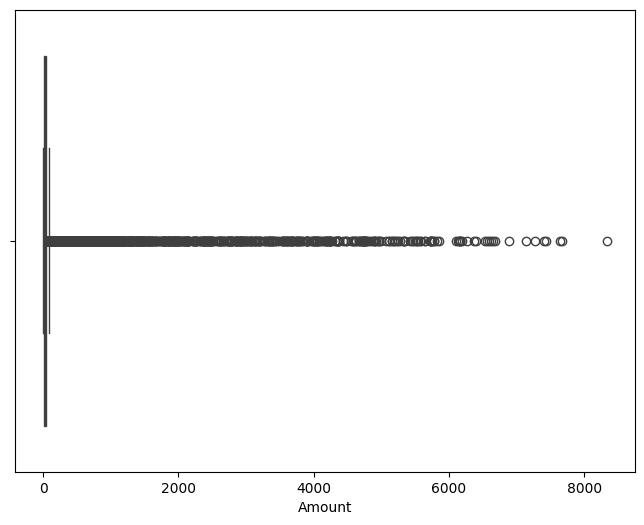

In [38]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="amount", data=df)
plt.xlabel("Amount")
plt.show()

In [39]:
df['amount'].max()

np.float64(8329.96)

In [40]:
df.nlargest(10, 'amount')

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
513394,158,'C702798720','2','M','28007','M732195782','28007','es_travel',8329.96,1
135692,48,'C806399525','2','F','28007','M732195782','28007','es_travel',7665.56,1
383889,122,'C1007572087','2','F','28007','M732195782','28007','es_travel',7635.41,1
6710,2,'C375144053','6','F','28007','M732195782','28007','es_travel',7432.48,1
329533,107,'C430880678','2','M','28007','M2080407379','28007','es_travel',7403.44,1
227774,77,'C1817318774','2','F','28007','M732195782','28007','es_travel',7272.41,1
456821,142,'C350034124','1','F','28007','M2080407379','28007','es_travel',7134.39,1
3744,1,'C1354768768','1','F','28007','M495352832','28007','es_travel',6888.30,1
411290,130,'C751887992','3','F','28007','M732195782','28007','es_travel',6679.23,1
143176,50,'C417267123','2','F','28007','M732195782','28007','es_travel',6649.49,1


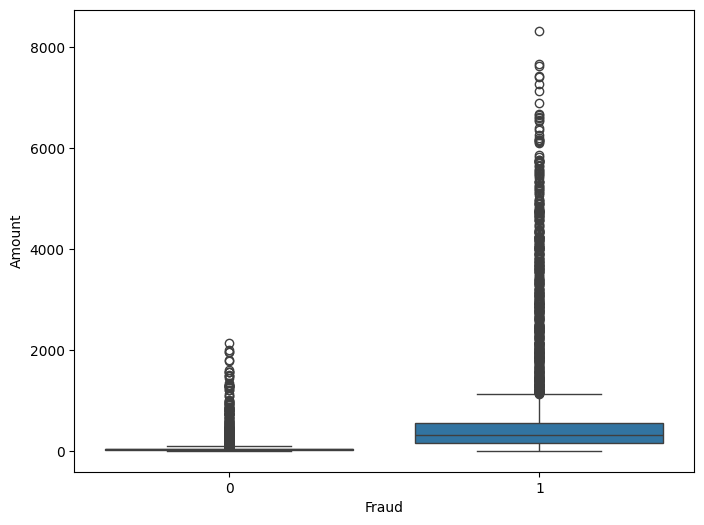

In [41]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="fraud", y="amount", data=df)
plt.xlabel("Fraud")
plt.ylabel("Amount")
plt.show()

In [42]:
df.groupby("fraud")['amount'].median()

fraud
0     26.610
1    319.175
Name: amount, dtype: float64

In [43]:
df['step'].unique()

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179])

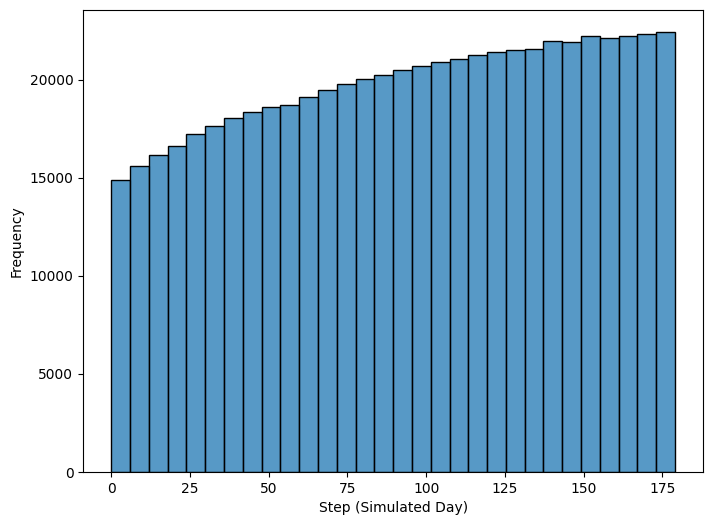

In [44]:
plt.figure(figsize=(8, 6))
sns.histplot(x="step", data=df, bins=30)
plt.xlabel("Step (Simulated Day)")
plt.ylabel("Frequency")
plt.show()

Observation — step distribution
- Transaction frequency gradually increases from step 0 to step 179.
- Later simulated days contain more transactions than earlier days.
- The distribution is not uniform across the 180 steps.

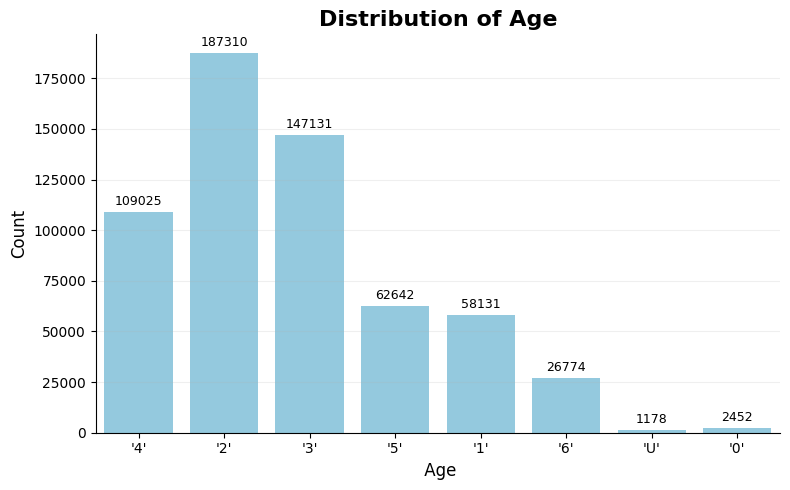

In [45]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['age'],
    color='skyblue'
)

plt.title("Distribution of Age",
          fontsize=16, fontweight='bold')

plt.xlabel(" Age", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Observation — Age distribution
- Age group '2' has the highest transaction count (187,310), followed by '3' (147,131).
- Age group 'U' (unknown) has the lowest count (1,178).
- Transaction records are concentrated in age groups '2', '3', and '4'.

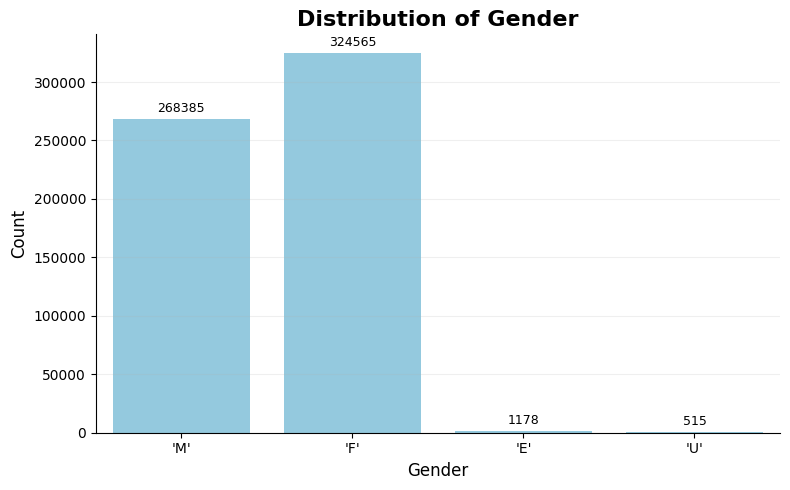

In [46]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['gender'],
    color='skyblue'
)

plt.title("Distribution of Gender",
          fontsize=16, fontweight='bold')

plt.xlabel("Gender", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Observation — Gender distribution
- Female (F) transactions are highest at 324,565, followed by male (M) transactions at 268,385.
- Enterprise (E) and unknown (U) categories have very few transactions compared with F and M.
- The distribution is heavily concentrated in the female and male categories.

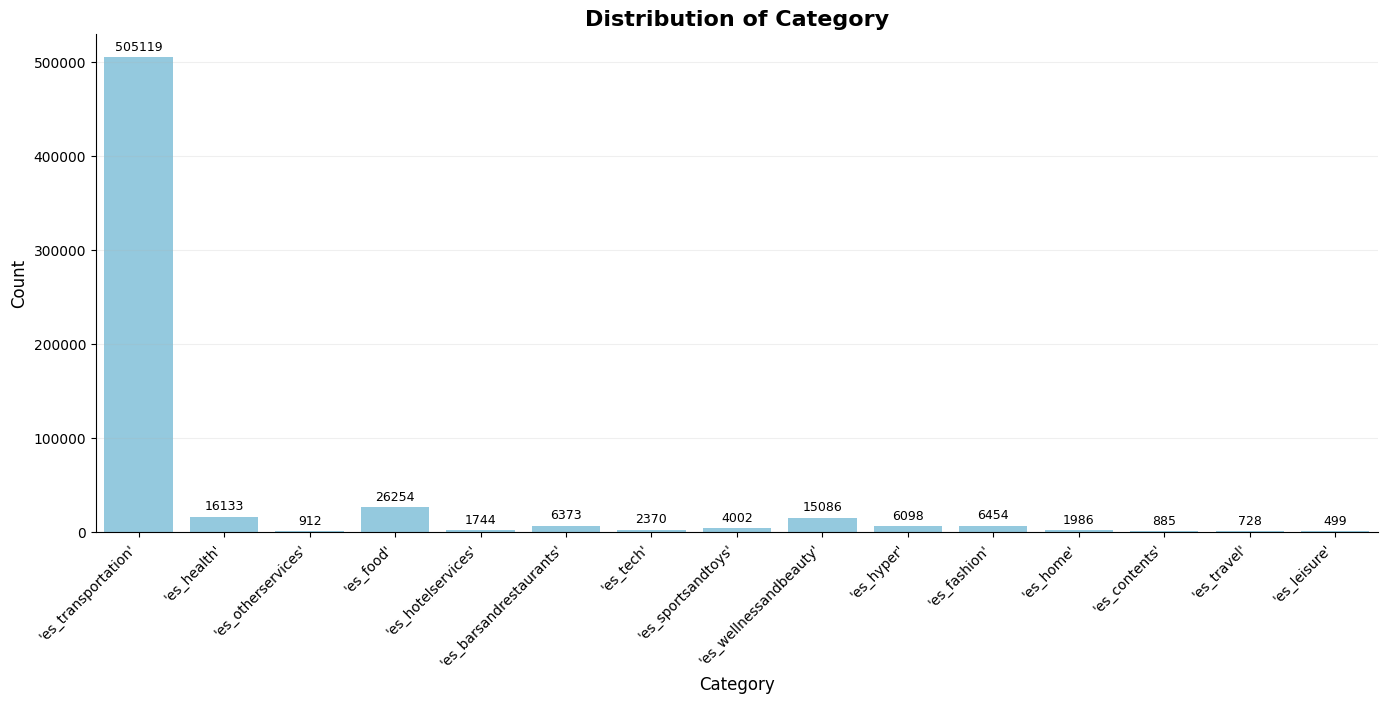

In [47]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    x=df['category'],
    color='skyblue'
)

plt.title("Distribution of Category",
          fontsize=16, fontweight='bold')

plt.xlabel("Category", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.show()

Observation — Category distribution
- es_transportation dominates with 505,119 transactions, far more than any other category.
- es_food (26,254) and es_health (16,133) are the next most frequent categories.
- Categories are highly imbalanced in frequency, with some categories having fewer than 1,000 transactions.

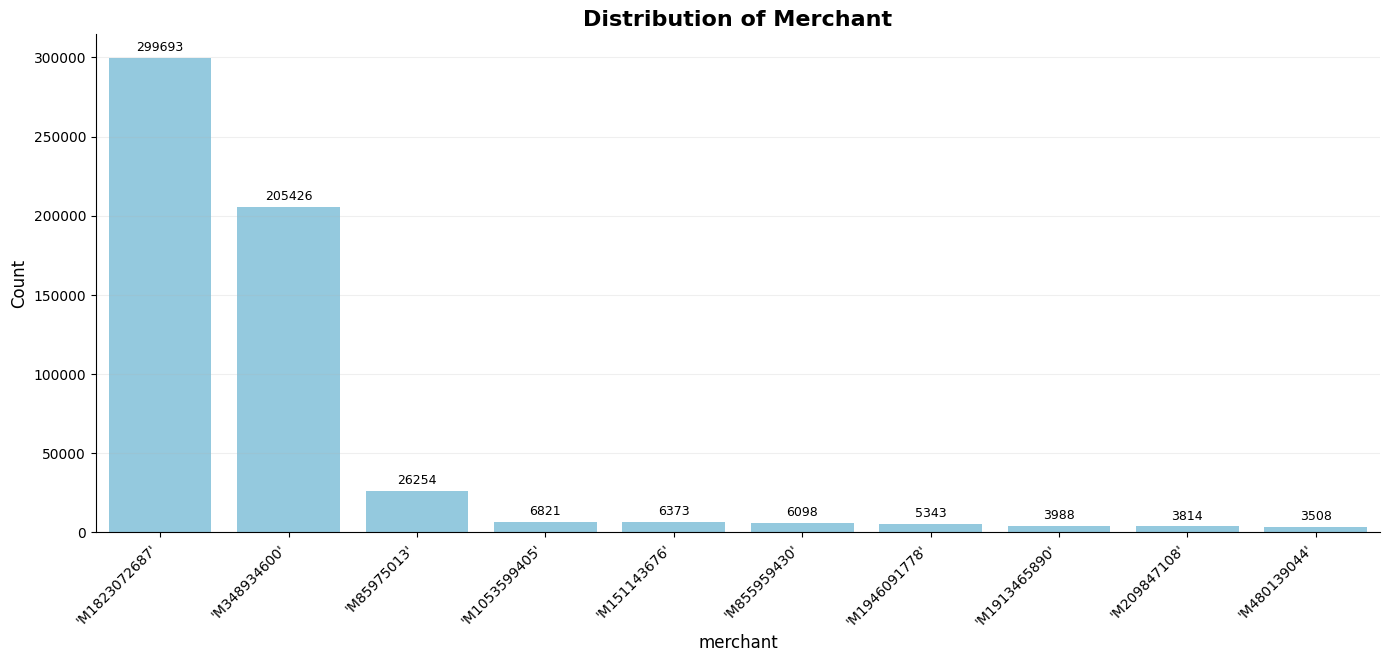

In [48]:
cat = df['merchant'].value_counts().head(10)
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    x=cat.index, y = cat.values, 
    color='skyblue'
)

plt.title("Distribution of Merchant",
          fontsize=16, fontweight='bold')

plt.xlabel("merchant", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.show()

Observation — Merchant distribution
- Merchant 'M1823072687' has the highest transaction count (299,693), followed by 'M348934600' (205,426).
- The remaining top 10 merchants have substantially fewer transactions, indicating that transaction volume is heavily concentrated among two merchants.

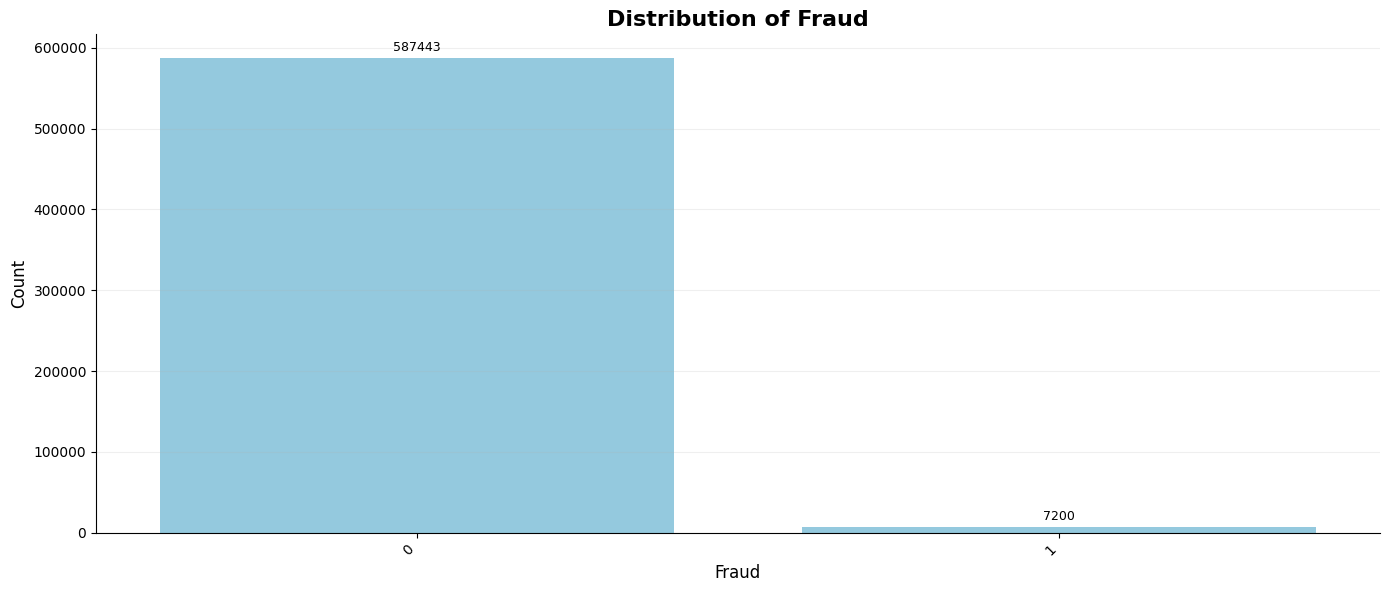

In [49]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    x=df['fraud'],
    color='skyblue'
)

plt.title("Distribution of Fraud",
          fontsize=16, fontweight='bold')

plt.xlabel("Fraud", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.show()

Observation — Fraud distribution
- Legitimate transactions (0) account for 587,443, while fraudulent transactions (1) account for only 7,200.
- The dataset is highly imbalanced, with fraud representing approximately 1.21% of all transactions.

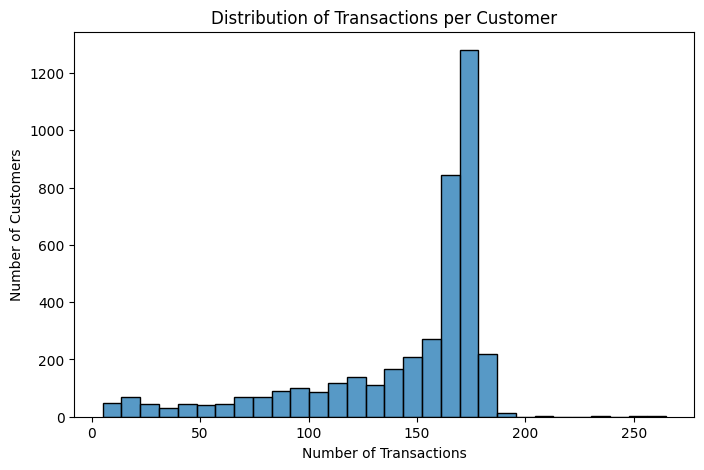

In [50]:
customer_counts = df['customer'].value_counts()

plt.figure(figsize=(8, 5))
sns.histplot(customer_counts, bins=30)
plt.title("Distribution of Transactions per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.show()

Most customers have approximately 160–180 transactions in the dataset.



The distribution is concentrated around 170–180 transactions per customer, with a tail toward lower transaction counts.



A small number of customers have substantially fewer or more transactions than the majority.

## Univariate Analysis Summary

- **Amount:** The distribution is strongly right-skewed, with most transactions having smaller amounts and a few very large values. The IQR method flagged 22.39% of transactions as potential outliers; these were retained for further investigation.
- **Step:** Transaction frequency generally increases across the 180 simulated days.
- **Age:** Age group `'2'` has the highest transaction count, while `'U'` has the lowest.
- **Gender:** Female transactions are more frequent than male transactions. Enterprise and unknown categories occur much less frequently.
- **Category:** `es_transportation` dominates the dataset, accounting for 505,119 transactions.
- **Merchant:** Transaction volume is concentrated among a few merchants, particularly `M1823072687` and `M348934600`.
- **Fraud:** The target is highly imbalanced: 587,443 legitimate transactions and 7,200 fraudulent transactions (approximately 1.21% fraud).
- **Customer activity:** Most customers have approximately 160–180 transactions in the dataset.

**Conclusion:** The dataset shows skewed transaction amounts, uneven category and merchant frequencies, and substantial class imbalance. These characteristics should be considered during feature engineering, model training, and evaluation. No data has been removed or modified during this analysis.

In [51]:
#BiVariate Analysis

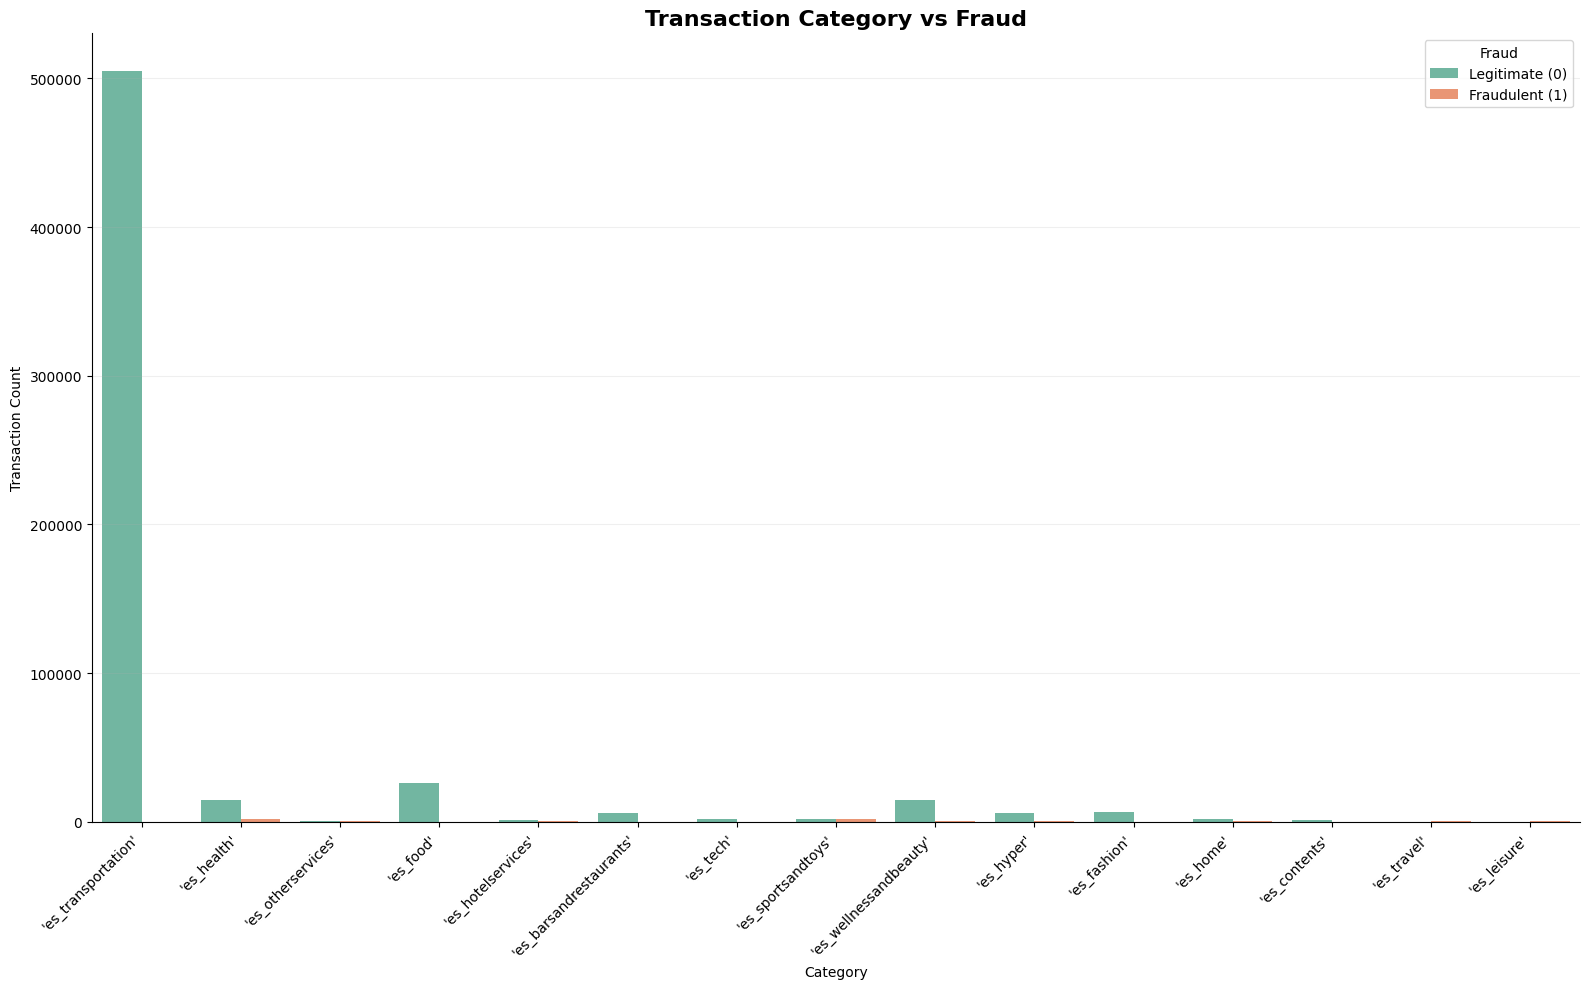

In [52]:
plt.figure(figsize=(16, 10))

ax = sns.countplot(
    data=df,
    x="category",
    hue="fraud",
    palette="Set2"
)

plt.title("Transaction Category vs Fraud",
          fontsize=16, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Transaction Count")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Fraud", labels=["Legitimate (0)", "Fraudulent (1)"])
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

**Observation: Transaction Category vs Fraud**

- Transaction volume varies significantly across categories.
- `es_transportation` accounts for the largest number of transactions.
- Legitimate transactions substantially outnumber fraudulent transactions in the overall dataset.
- Raw fraud counts do not directly indicate risk because categories have different transaction volumes.
- Therefore, fraud rate by category is a more meaningful metric for comparing the relative fraud risk of different categories.

In [53]:
fraud_rate = df.groupby('category')['fraud'].mean() * 100

fraud_rate = fraud_rate.sort_values(ascending=False)

print(fraud_rate)

category
'es_leisure'               94.989980
'es_travel'                79.395604
'es_sportsandtoys'         49.525237
'es_hotelservices'         31.422018
'es_otherservices'         25.000000
'es_home'                  15.206445
'es_health'                10.512614
'es_tech'                   6.666667
'es_wellnessandbeauty'      4.759380
'es_hyper'                  4.591669
'es_barsandrestaurants'     1.882944
'es_fashion'                1.797335
'es_contents'               0.000000
'es_food'                   0.000000
'es_transportation'         0.000000
Name: fraud, dtype: float64


**Observation: Fraud Rate by Transaction Category**

- `es_leisure` has the highest observed fraud rate at approximately 94.99%, followed by `es_travel` at 79.40%.
- `es_sportsandtoys` and `es_hotelservices` also show relatively high fraud rates.
- `es_transportation`, `es_food`, and `es_contents` have zero observed fraudulent transactions in this dataset.
- Fraud rates differ substantially across transaction categories, suggesting that `category` may be a useful predictive feature.
- These findings describe this dataset only. Categories with few transactions may have unstable fraud rates, and a high observed rate does not guarantee that a future transaction is fraudulent.

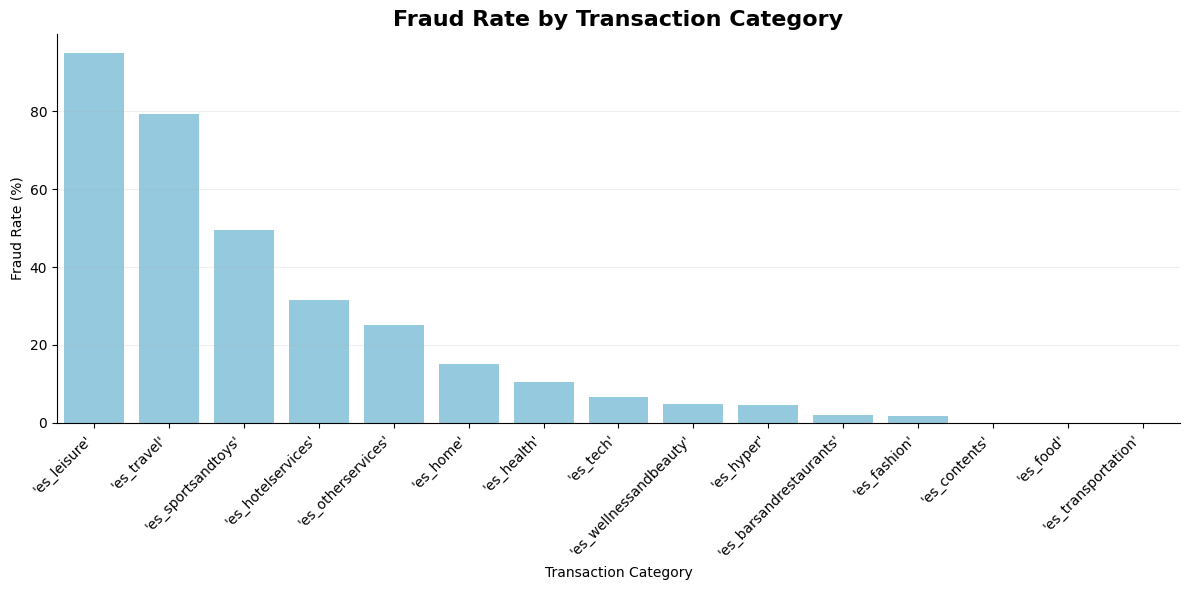

In [54]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=fraud_rate.index,
    y=fraud_rate.values,
    color='skyblue'
)

plt.title("Fraud Rate by Transaction Category",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

**Conclusion:** Fraud rates vary considerably across transaction categories. Categories such as `es_leisure`, `es_travel`, and `es_sportsandtoys` have much higher observed fraud rates than most other categories. Therefore, transaction category may provide useful information for distinguishing fraudulent from legitimate transactions. These relationships must be validated during model evaluation.

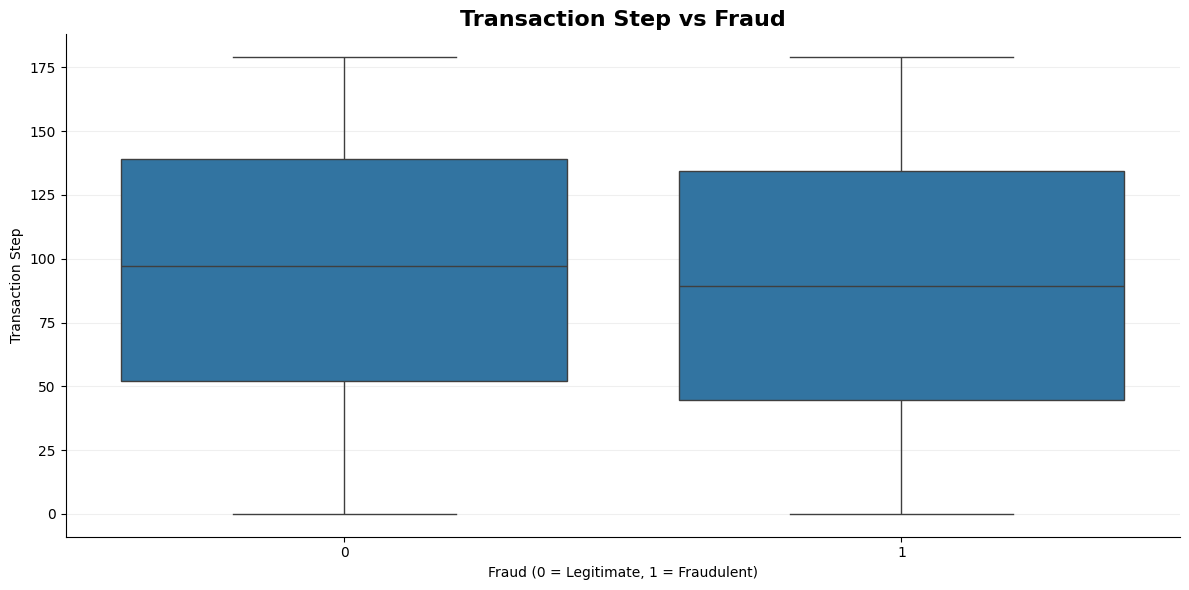

In [55]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='fraud',
    y='step'
)

plt.title("Transaction Step vs Fraud",
          fontsize=16, fontweight="bold")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Step")
plt.grid(axis='y', alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

**Conclusion:** The median transaction step is slightly lower for fraudulent transactions than for legitimate transactions. However, both groups have broadly overlapping distributions. Therefore, transaction step alone may have limited ability to distinguish fraud. Further analysis of fraud rates over time is needed to understand temporal patterns.

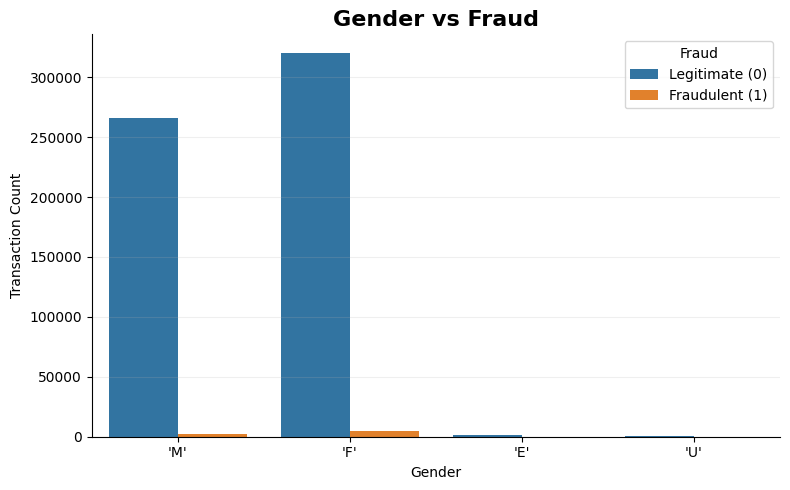

In [56]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='gender',
    hue='fraud'
)

plt.title("Gender vs Fraud",
          fontsize=16, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Transaction Count")
plt.legend(
    title="Fraud",
    labels=["Legitimate (0)", "Fraudulent (1)"]
)
plt.grid(axis='y', alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

**Conclusion: Gender vs Fraud**

Female transactions have a higher raw fraud count than male transactions in this dataset. However, the transaction volumes differ between categories, so this does not necessarily mean that female transactions have a higher fraud rate. Fraud rates should be compared across gender categories before drawing conclusions.

In [57]:
gender_fraud_rate = df.groupby('gender')['fraud'].mean() * 100

print(gender_fraud_rate.sort_values(ascending=False))

gender
'F'    1.465962
'M'    0.907279
'E'    0.594228
'U'    0.000000
Name: fraud, dtype: float64


**Conclusion: Gender vs Fraud**

The observed fraud rate differs across gender categories. Female transactions have a higher fraud rate (1.47%) than male transactions (0.91%) in this dataset. Gender may contain predictive information, but this association does not establish causation. Its usefulness and appropriateness should be evaluated carefully during model development.

In [58]:
fraud_merchants = (
    df[df['fraud'] == 1]['merchant']
    .value_counts()
    .head(10)
)

print(fraud_merchants)

merchant
'M480139044'     1634
'M980657600'     1472
'M732195782'      518
'M1198415165'     358
'M3697346'        290
'M855959430'      280
'M1888755466'     228
'M1873032707'     216
'M2122776122'     200
'M1741626453'     196
Name: count, dtype: int64


**Conclusion: Merchant vs Fraud**

Fraudulent transactions are not distributed equally across merchants. `M480139044` and `M980657600` have the highest observed fraud counts in the dataset. however these counts alone cannot establish that these merchants have the highest fraud risk. Their total transaction volumes and merchant-level fraud rates must also be examined.

In [59]:
merchant_fraud_rate = (
    df.groupby('merchant')['fraud']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(merchant_fraud_rate.head(10))

merchant
'M1294758098'    96.335079
'M3697346'       94.155844
'M1873032707'    86.400000
'M732195782'     85.197368
'M980657600'     83.210854
'M1353266412'    82.051282
'M857378720'     75.409836
'M2080407379'    75.000000
'M2011752106'    68.032787
'M17379832'      63.120567
Name: fraud, dtype: float64


**Conclusion: Merchant vs Fraud**

Fraud rates vary considerably across merchant IDs. Some merchants have a very high proportion of fraudulent transactions in this dataset. However, high fraud rates may be unstable for merchants with few transactions, and these results do not establish that a merchant is responsible for fraud. Merchant transaction volume should be examined alongside fraud rate before interpreting these patterns.

In [60]:
top_merchants = merchant_fraud_rate.head(10).index

merchant_summary = (
    df[df['merchant'].isin(top_merchants)]
    .groupby('merchant')
    .agg(
        total_transactions=('fraud', 'size'),
        fraudulent_transactions=('fraud', 'sum'),
        fraud_rate=('fraud', 'mean')
    )
)

merchant_summary['fraud_rate'] *= 100

print(merchant_summary.sort_values('fraud_rate', ascending=False))

               total_transactions  fraudulent_transactions  fraud_rate
merchant                                                              
'M1294758098'                 191                      184   96.335079
'M3697346'                    308                      290   94.155844
'M1873032707'                 250                      216   86.400000
'M732195782'                  608                      518   85.197368
'M980657600'                 1769                     1472   83.210854
'M1353266412'                  78                       64   82.051282
'M857378720'                  122                       92   75.409836
'M2080407379'                  48                       36   75.000000
'M2011752106'                 244                      166   68.032787
'M17379832'                   282                      178   63.120567


**Observation: Merchant Transaction Volume and Fraud Rate**

The analysis compares total transaction volume, fraudulent transaction count, and fraud rate for the 10 merchants with the highest observed fraud rates.

- `M1294758098` has the highest fraud rate at 96.34%, with 184 fraudulent transactions out of 191.
- `M980657600` has 1,472 fraudulent transactions out of 1,769, giving a fraud rate of 83.21%.
- `M2080407379` has a 75% fraud rate, but this is based on only 48 transactions.

This comparison shows why fraud rates should be interpreted alongside transaction counts. These patterns apply to the dataset and do not establish real-world merchant risk.

In [61]:
#Munlti variate Analysis

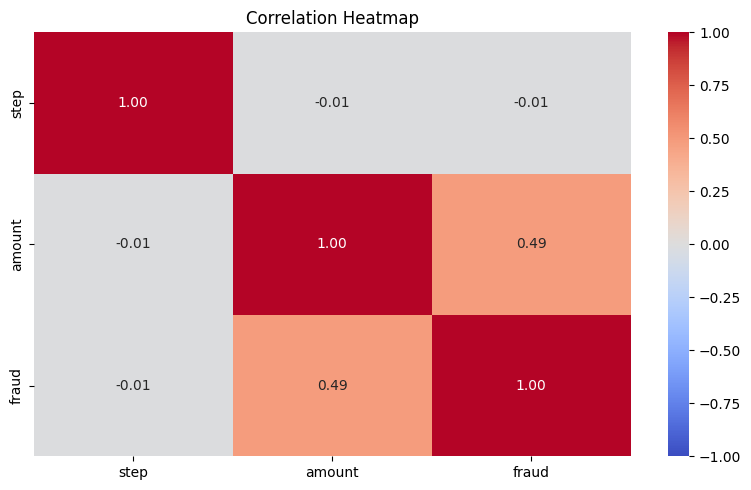

In [62]:
# Select numerical columns for correlation analysis
numeric_df = df[['step', 'amount', 'fraud']]

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Observation: Correlation Analysis**

The correlation heatmap shows a moderate positive correlation between transaction amount and fraud (r = 0.49). In contrast, transaction step has almost zero linear correlation with both amount (r = −0.01) and fraud (r = −0.01). This suggests that transaction amount has a stronger linear association with the fraud label than transaction step. However, feature usefulness must ultimately be evaluated using an appropriate machine-learning model and validation strategy.

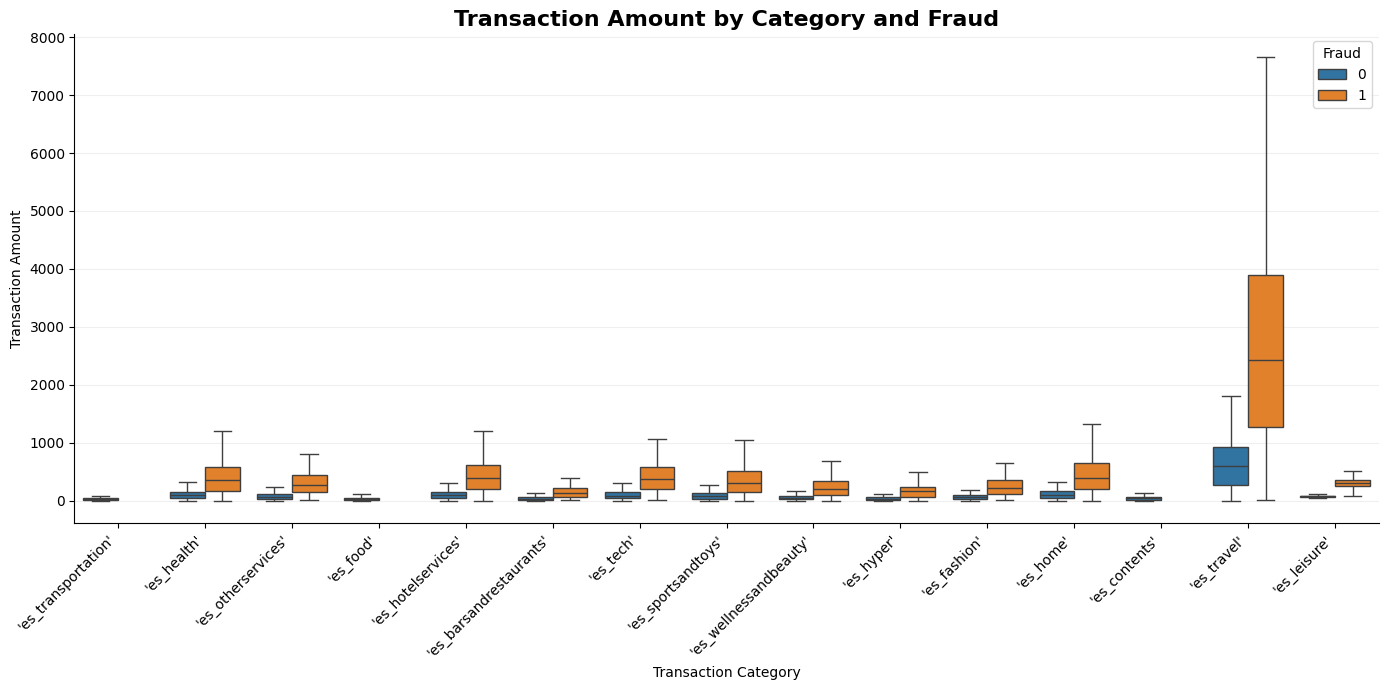

In [63]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x='category',
    y='amount',
    hue='fraud',
    showfliers=False
)

plt.title("Transaction Amount by Category and Fraud",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Category")
plt.ylabel("Transaction Amount")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Fraud")
plt.grid(axis='y', alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

**Observation: Transaction Amount by Category and Fraud**

The box plot indicates that fraudulent transactions generally have higher transaction amounts and greater variability in several categories, particularly `es_travel`. However, the extent of the difference varies across categories, and some categories show more overlap between legitimate and fraudulent transactions. This suggests that transaction amount and category may provide complementary information for fraud prediction. These relationships require validation during model evaluation.

In [64]:
amount_summary = df.groupby(
    ['category', 'fraud']
)['amount'].median().unstack()

amount_summary.columns = ['Legitimate', 'Fraudulent']

print(amount_summary.round(2))

                         Legitimate  Fraudulent
category                                       
'es_barsandrestaurants'       35.80      135.96
'es_contents'                 38.43         NaN
'es_fashion'                  54.87      224.68
'es_food'                     33.47         NaN
'es_health'                   89.11      353.36
'es_home'                     97.71      391.67
'es_hotelservices'           100.38      382.49
'es_hyper'                    35.42      163.78
'es_leisure'                  73.31      300.59
'es_otherservices'            65.80      272.18
'es_sportsandtoys'            78.74      311.42
'es_tech'                     84.22      364.43
'es_transportation'           24.96         NaN
'es_travel'                  601.88     2432.65
'es_wellnessandbeauty'        49.96      198.32


**Conclusion: Amount, Category and Fraud**

The median transaction amount for fraudulent transactions is higher than the legitimate median in every category where both groups contain observations. The difference is particularly pronounced in `es_travel`, where the fraudulent median is 2,432.65 compared with 601.88 for legitimate transactions. Some categories have no fraudulent observations, resulting in missing (`NaN`) fraudulent medians. These findings suggest that transaction amount and category together may be useful for fraud prediction, subject to validation during model evaluation.

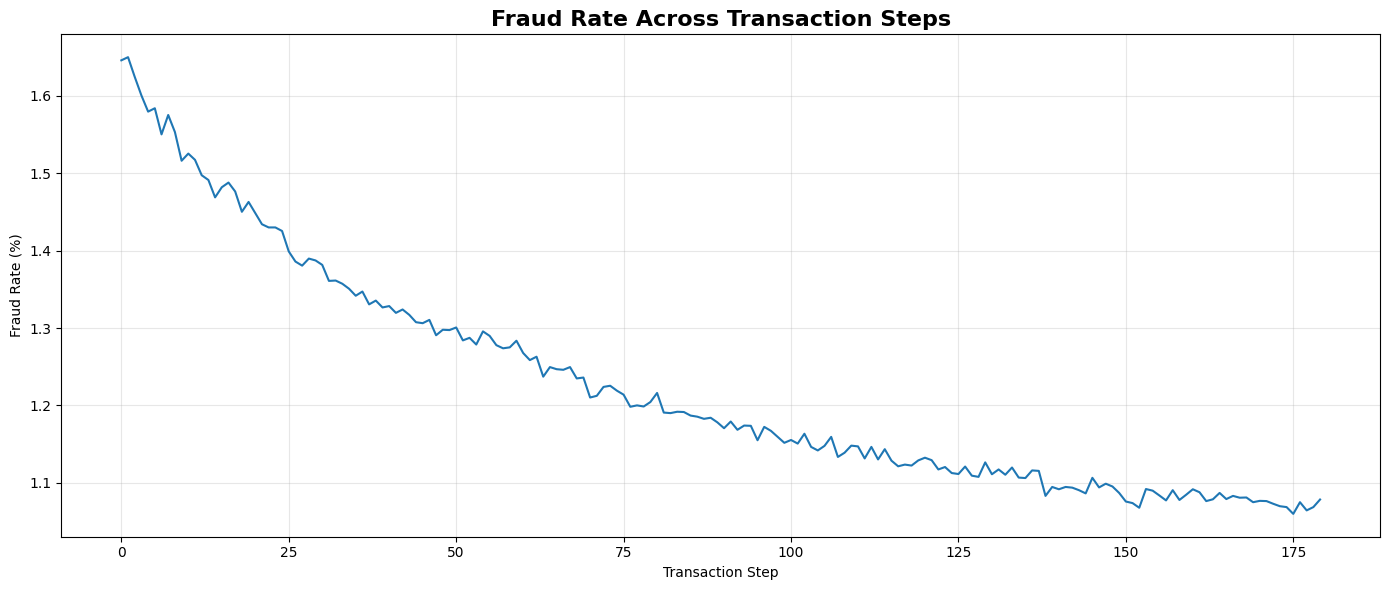

In [65]:
fraud_by_step = df.groupby('step')['fraud'].mean() * 100

plt.figure(figsize=(14, 6))

plt.plot(fraud_by_step.index, fraud_by_step.values)

plt.title("Fraud Rate Across Transaction Steps",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Step")
plt.ylabel("Fraud Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation: Fraud Rate Across Transaction Steps**

The fraud rate shows a general downward trend across transaction steps, decreasing from approximately 1.65% at the beginning to around 1.07% near the end. Although small fluctuations occur, the overall pattern suggests that fraud prevalence changes over time in this dataset. Transaction step may therefore provide useful temporal information, but its predictive value must be validated during model evaluation.

In [66]:
# Check the number of unique values
print("zipcodeOri:", df['zipcodeOri'].nunique())
print("zipMerchant:", df['zipMerchant'].nunique())

zipcodeOri: 1
zipMerchant: 1


df.drop(columns=['zipcodeOri', 'zipMerchant'], inplace=True)

In [67]:
df.drop(columns=['zipcodeOri', 'zipMerchant'], inplace=True)

In [68]:
print(df.shape)
print(df.columns.tolist())

(594643, 8)
['step', 'customer', 'age', 'gender', 'merchant', 'category', 'amount', 'fraud']


In [69]:
print(df.dtypes)

step          int64
customer     object
age          object
gender       object
merchant     object
category     object
amount      float64
fraud         int64
dtype: object


In [70]:
print("Categorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=['int64', 'float64']).columns.tolist())

Categorical columns:
['customer', 'age', 'gender', 'merchant', 'category']

Numerical columns:
['step', 'amount', 'fraud']


In [71]:
print("Unique customers:", df['customer'].nunique())
print("Unique merchants:", df['merchant'].nunique())

Unique customers: 4112
Unique merchants: 50


In [73]:
X = df.drop(columns=['fraud', 'customer'])
Y = df['fraud']

print("X shape:", X.shape)
print("y shape:", Y.shape)

X shape: (594643, 6)
y shape: (594643,)


In [77]:
print(Y.value_counts())
print("\nFraud percentage:")
print((Y.mean() * 100).round(2), "%")

fraud
0    587443
1      7200
Name: count, dtype: int64

Fraud percentage:
1.21 %


## Exploratory Experiments: Initial Model Development

The following experiments were conducted during the initial stages of model development. A stratified random train-test split was used to establish baseline performance for Logistic Regression and Decision Tree models.

These experiments helped explore class imbalance, precision-recall trade-offs, and the effect of different decision thresholds.

**Important:** These results are exploratory, not the final evaluation. The test set was also used during earlier threshold experimentation, so those results should not be treated as an independent final benchmark.

The final modeling workflow later in this notebook uses chronological data splits to better reflect the task of predicting fraud on future transactions.

In [78]:
from sklearn.model_selection import train_test_split

In [80]:

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [81]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nTraining fraud rate:", round(Y_train.mean() * 100, 2), "%")
print("Testing fraud rate:", round(Y_test.mean() * 100, 2), "%")

X_train: (475714, 6)
X_test: (118929, 6)

Training fraud rate: 1.21 %
Testing fraud rate: 1.21 %


In [82]:
categorical_cols = ['age', 'gender', 'merchant', 'category']
numerical_cols = ['step', 'amount']

print("Categorical:", X_train[categorical_cols].nunique())
print("Numerical:", numerical_cols)

Categorical: age          8
gender       4
merchant    50
category    15
dtype: int64
Numerical: ['step', 'amount']


In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ['age', 'gender', 'merchant', 'category']
numerical_cols = ['step', 'amount']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (475714, 79)
Processed testing shape: (118929, 79)


In [84]:
from sklearn.linear_model import LogisticRegression

In [85]:
model = LogisticRegression(max_iter=1000,
    class_weight='balanced',
    random_state=42)

In [86]:
model

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [87]:
model.fit(X_train_processed, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [88]:
from sklearn.metrics import classification_report, confusion_matrix


y_pred = model.predict(X_test_processed)

# Evaluate predictions
print("Confusion Matrix:")
print(confusion_matrix(Y_test, y_pred))

print("\nClassification Report:")
print(classification_report(Y_test, y_pred))

Confusion Matrix:
[[113685   3804]
 [    24   1416]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98    117489
           1       0.27      0.98      0.43      1440

    accuracy                           0.97    118929
   macro avg       0.64      0.98      0.70    118929
weighted avg       0.99      0.97      0.98    118929



**Baseline Model: Logistic Regression**

Logistic Regression was trained with `class_weight='balanced'` to account for class imbalance.

On the test set, the model achieved approximately 98.33% fraud recall, identifying 1,416 of 1,440 fraudulent transactions. However, fraud precision was only 27.12%, with 3,804 false-positive predictions. The fraud-class F1-score was approximately 0.43.

These results show that the model prioritizes detecting fraud but generates a substantial number of false alarms. Further evaluation, including precision-recall analysis and decision-threshold tuning, is needed to find a more practical balance.

Average Precision (PR-AUC): 0.8768


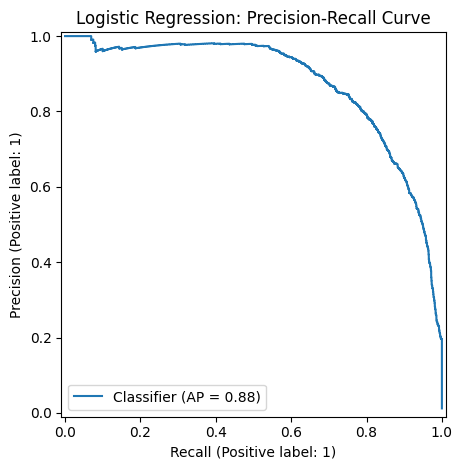

In [89]:
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
import matplotlib.pyplot as plt

y_prob = model.predict_proba(X_test_processed)[:, 1]

pr_auc = average_precision_score(Y_test, y_prob)
print("Average Precision (PR-AUC):", round(pr_auc, 4))

PrecisionRecallDisplay.from_predictions(Y_test, y_prob)
plt.title("Logistic Regression: Precision-Recall Curve")
plt.tight_layout()
plt.show()

**Observation: Logistic Regression Precision-Recall Analysis**

The Logistic Regression model achieved an Average Precision (AP) score of 0.88 on the test set. The precision-recall curve indicates that the model can maintain relatively high precision at moderate recall levels, but precision declines as recall approaches 100%. This demonstrates the trade-off between detecting more fraudulent transactions and generating false-positive alerts. Decision-threshold tuning may improve the balance between fraud detection and false alarms.

In [90]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train_processed, Y_train)

y_pred_dt = dt_model.predict(X_test_processed)

In [91]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(Y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(Y_test, y_pred_dt))

Confusion Matrix:
[[117156    333]
 [   376   1064]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    117489
           1       0.76      0.74      0.75      1440

    accuracy                           0.99    118929
   macro avg       0.88      0.87      0.87    118929
weighted avg       0.99      0.99      0.99    118929



**Observation: Decision Tree Evaluation**

The Decision Tree achieved a fraud precision of approximately 76.1%, recall of 73.9%, and F1-score of 0.75. It correctly identified 1,064 of 1,440 fraudulent transactions, while producing 333 false positives. Compared with Logistic Regression at its default classification threshold, the Decision Tree provides higher precision and F1-score but lower recall. This highlights the trade-off between reducing false alarms and detecting more fraudulent transactions.

Logistic Regression AP: 0.8768
Decision Tree AP: 0.5659


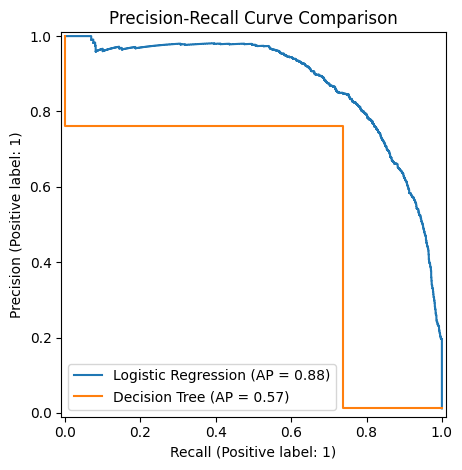

In [92]:
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay


y_prob_dt = dt_model.predict_proba(X_test_processed)[:, 1]

ap_dt = average_precision_score(Y_test, y_prob_dt)

print("Logistic Regression AP:", round(pr_auc, 4))
print("Decision Tree AP:", round(ap_dt, 4))

PrecisionRecallDisplay.from_predictions(
    Y_test, y_prob,
    name="Logistic Regression"
)

PrecisionRecallDisplay.from_predictions(
    Y_test, y_prob_dt,
    name="Decision Tree",
    ax=plt.gca()
)

plt.title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.show()

**Observation: Precision-Recall Curve Comparison**

Logistic Regression achieved an Average Precision (AP) of 0.88, outperforming the Decision Tree's AP of 0.57. This indicates that Logistic Regression provides better overall precision-recall ranking performance on the test set. Although the Decision Tree achieved higher precision and F1-score at the default threshold, its lower AP suggests weaker performance across thresholds. Threshold selection and further validation are needed before selecting the final model.

In [93]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    Y_test, y_prob
)

# Find thresholds with at least 80% fraud recall
valid = recall[:-1] >= 0.80

if valid.any():
    best_idx = precision[:-1][valid].argmax()
    best_threshold = thresholds[valid][best_idx]

    print("Threshold:", round(best_threshold, 4))
    print("Precision:", round(precision[:-1][valid][best_idx], 4))
    print("Recall:", round(recall[:-1][valid][best_idx], 4))
else:
    print("No threshold meets the recall requirement.")

Threshold: 0.9756
Precision: 0.7928
Recall: 0.8


Split training data into training and validation sets

In [94]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    Y_train,
    test_size=0.2,
    random_state=42,
    stratify=Y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

print("Training fraud rate:", round(y_train_sub.mean() * 100, 2), "%")
print("Validation fraud rate:", round(y_val.mean() * 100, 2), "%")

Training subset: (380571, 6)
Validation set: (95143, 6)
Training fraud rate: 1.21 %
Validation fraud rate: 1.21 %


In [95]:
from sklearn.base import clone

preprocessor_val = clone(preprocessor)

X_train_sub_processed = preprocessor_val.fit_transform(X_train_sub)
X_val_processed = preprocessor_val.transform(X_val)

print("Training subset processed:", X_train_sub_processed.shape)
print("Validation processed:", X_val_processed.shape)

Training subset processed: (380571, 79)
Validation processed: (95143, 79)


In [96]:
from sklearn.linear_model import LogisticRegression

lr_model_val = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)


lr_model_val.fit(X_train_sub_processed, y_train_sub)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [98]:
y_val_prob = lr_model_val.predict_proba(X_val_processed)[:, 1]

print("Validation predictions:", len(y_val_prob))
print("Validation samples:", len(y_val))

Validation predictions: 95143
Validation samples: 95143


In [99]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

valid = recall[:-1] >= 0.80

if valid.any():
    valid_indices = valid.nonzero()[0]
    best_idx = valid_indices[precision[:-1][valid].argmax()]

    best_threshold = thresholds[best_idx]

    print("Best threshold:", round(best_threshold, 4))
    print("Validation precision:", round(precision[best_idx], 4))
    print("Validation recall:", round(recall[best_idx], 4))
else:
    print("No threshold meets the recall requirement.")

Best threshold: 0.9753
Validation precision: 0.8003
Validation recall: 0.8003


In [101]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

# Predict fraud probabilities on the untouched test set
y_test_prob = lr_model_val.predict_proba(X_test_processed)[:, 1]

# Apply the threshold selected using validation data
y_test_pred_tuned = (y_test_prob >= best_threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(Y_test, y_test_pred_tuned))

print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred_tuned))

print(
    "Test Average Precision:",
    round(average_precision_score(Y_test, y_test_prob), 4)
)

Confusion Matrix:
[[117197    292]
 [   293   1147]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    117489
           1       0.80      0.80      0.80      1440

    accuracy                           1.00    118929
   macro avg       0.90      0.90      0.90    118929
weighted avg       1.00      1.00      1.00    118929

Test Average Precision: 0.8776


**Final Threshold-Tuned Logistic Regression Evaluation**

The Logistic Regression model was evaluated on the held-out test set using a decision threshold of 0.9753, selected on the validation set with a target fraud recall of at least 80%.

The model achieved approximately 79.71% fraud precision, 79.65% fraud recall, and a fraud F1-score of 0.80. It correctly detected 1,147 of 1,440 fraudulent transactions and produced 292 false positives. The Average Precision score was 0.8776.

Compared with the default threshold, threshold tuning substantially reduced false-positive predictions while retaining useful fraud detection performance. The results provide a baseline for further model comparison and validation.

In [102]:
from sklearn.tree import DecisionTreeClassifier

dt_model_val = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model_val.fit(X_train_sub_processed, y_train_sub)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [103]:
y_val_prob_dt = dt_model_val.predict_proba(
    X_val_processed
)[:, 1]

In [104]:
from sklearn.metrics import average_precision_score

ap_dt_val = average_precision_score(
    y_val,
    y_val_prob_dt
)

print("Decision Tree Validation AP:", round(ap_dt_val, 4))

Decision Tree Validation AP: 0.5774


**Validation Model Comparison**

Logistic Regression achieved an Average Precision score of approximately 0.88, while the Decision Tree achieved 0.5774 on the validation set. This indicates that Logistic Regression ranks fraudulent transactions more effectively across classification thresholds in the current experimental setup. The Decision Tree may still be useful after tuning, but Logistic Regression is currently the stronger candidate.

In [105]:
from sklearn.metrics import classification_report

y_val_pred_dt = dt_model_val.predict(X_val_processed)

print(classification_report(y_val, y_val_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93991
           1       0.77      0.75      0.76      1152

    accuracy                           0.99     95143
   macro avg       0.88      0.87      0.88     95143
weighted avg       0.99      0.99      0.99     95143



**Validation Model Comparison**

On the validation set, threshold-tuned Logistic Regression achieved approximately 80% fraud precision and recall, compared with approximately 77% precision and 75% recall for the Decision Tree at its default threshold. Logistic Regression also achieved higher Average Precision (approximately 0.88 versus 0.5774). These results make Logistic Regression the stronger candidate in the current experiment, although further validation is needed before final model selection.

In [106]:
customer_summary = df.groupby('customer').agg(
    transaction_count=('amount', 'size'),
    average_amount=('amount', 'mean'),
    median_amount=('amount', 'median'),
    maximum_amount=('amount', 'max')
)

print(customer_summary.head())

               transaction_count  average_amount  median_amount  \
customer                                                          
'C1000148617'                131       35.091908          26.14   
'C100045114'                 109       90.336239          35.13   
'C1000699316'                 94       38.154894          28.32   
'C1001065306'                 30      204.754667         103.68   
'C1002658784'                131       34.253282          29.94   

               maximum_amount  
customer                       
'C1000148617'          323.64  
'C100045114'          3902.93  
'C1000699316'          326.34  
'C1001065306'         1260.94  
'C1002658784'          197.30  


In [107]:
print(df[['step', 'customer', 'amount', 'fraud']].head(10))

   step       customer  amount  fraud
0     0  'C1093826151'    4.55      0
1     0   'C352968107'   39.68      0
2     0  'C2054744914'   26.89      0
3     0  'C1760612790'   17.25      0
4     0   'C757503768'   35.72      0
5     0  'C1315400589'   25.81      0
6     0   'C765155274'    9.10      0
7     0   'C202531238'   21.17      0
8     0   'C105845174'   32.40      0
9     0    'C39858251'   35.40      0


In [108]:
customer_steps = df.groupby('customer')['step'].nunique()

print("Customers appearing in multiple steps:",
      (customer_steps > 1).sum())

print("Customers appearing in only one step:",
      (customer_steps == 1).sum())

print("\nSteps per customer:")
print(customer_steps.describe())

Customers appearing in multiple steps: 4112
Customers appearing in only one step: 0

Steps per customer:
count    4112.000000
mean      139.137403
std        42.239334
min         3.000000
25%       124.000000
50%       161.000000
75%       167.000000
max       177.000000
Name: step, dtype: float64


In [109]:
df = df.sort_values(['step', 'customer']).copy()

customer_history = (
    df.groupby(['customer', 'step'])['amount']
      .agg(['count', 'sum'])
      .groupby(level=0)
      .cumsum()
)

# Remove the current step so only earlier steps remain
customer_history['previous_transaction_count'] = (
    customer_history.groupby(level=0)['count'].shift(1)
)

customer_history['previous_amount_sum'] = (
    customer_history.groupby(level=0)['sum'].shift(1)
)

customer_history['previous_average_amount'] = (
    customer_history['previous_amount_sum']
    / customer_history['previous_transaction_count']
)

print(customer_history.head(10))

                    count     sum  previous_transaction_count  \
customer      step                                              
'C1000148617' 30        1  143.87                         NaN   
              38        2  160.56                         1.0   
              42        3  216.74                         2.0   
              43        4  231.48                         3.0   
              44        5  278.90                         4.0   
              45        6  280.61                         5.0   
              46        7  315.40                         6.0   
              47        8  370.54                         7.0   
              48        9  385.38                         8.0   
              49       10  398.61                         9.0   

                    previous_amount_sum  previous_average_amount  
customer      step                                                
'C1000148617' 30                    NaN                      NaN  
              38  

In [110]:
df = df.sort_values(['customer', 'step']).copy()

customer_history = df.groupby('customer').apply(
    lambda group: pd.DataFrame({
        'previous_transaction_count': (
            group.groupby('step')['amount'].transform('size')
            .groupby(group['step']).first().shift(1).expanding().sum()
        ),
    }),
    include_groups=False
)

In [111]:
print(customer_history.index.names)
print(customer_history.head(10))
print(customer_history.isna().sum())

['customer', 'step']
                    previous_transaction_count
customer      step                            
'C1000148617' 30                           NaN
              38                           1.0
              42                           2.0
              43                           3.0
              44                           4.0
              45                           5.0
              46                           6.0
              47                           7.0
              48                           8.0
              49                           9.0
previous_transaction_count    4112
dtype: int64


In [112]:
# Count transactions and sum amounts per customer per step
step_summary = (
    df.groupby(['customer', 'step'])['amount']
      .agg(step_transaction_count='size', step_amount_sum='sum')
      .reset_index()
      .sort_values(['customer', 'step'])
)

# Calculate historical totals using strictly earlier steps
step_summary['previous_transaction_count'] = (
    step_summary.groupby('customer')['step_transaction_count']
    .transform(lambda s: s.cumsum().shift(1))
)

step_summary['previous_amount_sum'] = (
    step_summary.groupby('customer')['step_amount_sum']
    .transform(lambda s: s.cumsum().shift(1))
)

step_summary['previous_average_amount'] = (
    step_summary['previous_amount_sum']
    / step_summary['previous_transaction_count']
)

print(step_summary.head(10))


        customer  step  step_transaction_count  step_amount_sum  \
0  'C1000148617'    30                       1           143.87   
1  'C1000148617'    38                       1            16.69   
2  'C1000148617'    42                       1            56.18   
3  'C1000148617'    43                       1            14.74   
4  'C1000148617'    44                       1            47.42   
5  'C1000148617'    45                       1             1.71   
6  'C1000148617'    46                       1            34.79   
7  'C1000148617'    47                       1            55.14   
8  'C1000148617'    48                       1            14.84   
9  'C1000148617'    49                       1            13.23   

   previous_transaction_count  previous_amount_sum  previous_average_amount  
0                         NaN                  NaN                      NaN  
1                         1.0               143.87               143.870000  
2                         2.

In [113]:
print("Total customer-step records:", len(step_summary))

print("\nMissing historical values:")
print(
    step_summary[
        [
            'previous_transaction_count',
            'previous_amount_sum',
            'previous_average_amount'
        ]
    ].isna().sum()
)

print("\nHistorical feature statistics:")
print(
    step_summary[
        [
            'previous_transaction_count',
            'previous_average_amount'
        ]
    ].describe()
)

Total customer-step records: 572133

Missing historical values:
previous_transaction_count    4112
previous_amount_sum           4112
previous_average_amount       4112
dtype: int64

Historical feature statistics:
       previous_transaction_count  previous_average_amount
count               568021.000000            568021.000000
mean                    78.543774                40.311551
std                     47.939002                51.212016
min                      1.000000                 0.050000
25%                     37.000000                28.809518
50%                     76.000000                31.500796
75%                    118.000000                36.028333
max                    263.000000              6888.300000


In [114]:
history_features = step_summary[
    [
        'customer',
        'step',
        'previous_transaction_count',
        'previous_amount_sum',
        'previous_average_amount'
    ]
]

df = df.merge(
    history_features,
    on=['customer', 'step'],
    how='left',
    validate='many_to_one'
)

print("Updated dataset shape:", df.shape)
print(df.head())

Updated dataset shape: (594643, 11)
   step       customer  age gender       merchant             category  \
0    30  'C1000148617'  '5'    'M'  'M1888755466'   'es_otherservices'   
1    38  'C1000148617'  '5'    'M'  'M1741626453'   'es_sportsandtoys'   
2    42  'C1000148617'  '5'    'M'  'M1888755466'   'es_otherservices'   
3    43  'C1000148617'  '5'    'M'   'M840466850'            'es_tech'   
4    44  'C1000148617'  '5'    'M'  'M1823072687'  'es_transportation'   

   amount  fraud  previous_transaction_count  previous_amount_sum  \
0  143.87      0                         NaN                  NaN   
1   16.69      0                         1.0               143.87   
2   56.18      0                         2.0               160.56   
3   14.74      0                         3.0               216.74   
4   47.42      0                         4.0               231.48   

   previous_average_amount  
0                      NaN  
1               143.870000  
2                

In [128]:
print("Original transaction count:", 594643)
print("Current transaction count:", len(df))

print("\nDuplicate transactions added by merge:",
      len(df) - 594643)

print("\nHistorical feature missing values:")
print(
    df[
        [
            'previous_transaction_count',
            'previous_amount_sum',
            'previous_average_amount'
        ]
    ].isna().sum()
)

print("\nSample transactions with history:")
print(
    df.loc[
        df['previous_transaction_count'].notna(),
        [
            'customer',
            'step',
            'amount',
            'previous_transaction_count',
            'previous_average_amount',
            'fraud'
        ]
    ].head()
)

Original transaction count: 594643
Current transaction count: 594643

Duplicate transactions added by merge: 0

Historical feature missing values:
previous_transaction_count    4160
previous_amount_sum           4160
previous_average_amount       4160
dtype: int64

Sample transactions with history:
        customer  step  amount  previous_transaction_count  \
1  'C1000148617'    38   16.69                         1.0   
2  'C1000148617'    42   56.18                         2.0   
3  'C1000148617'    43   14.74                         3.0   
4  'C1000148617'    44   47.42                         4.0   
5  'C1000148617'    45    1.71                         5.0   

   previous_average_amount  fraud  
1               143.870000      0  
2                80.280000      0  
3                72.246667      0  
4                57.870000      0  
5                55.780000      0  


In [129]:
# Number of rows per customer-step combination
transactions_per_step = df.groupby(
    ['customer', 'step']
).size()

print("Customer-step groups:", len(transactions_per_step))
print("Groups with multiple transactions:",
      (transactions_per_step > 1).sum())

print("\nCustomers with missing historical values:")
missing_history = df[
    df['previous_transaction_count'].isna()
]

print("Missing rows:", len(missing_history))
print("Distinct customers:",
      missing_history['customer'].nunique())
print("Distinct customer-step pairs:",
      missing_history[['customer', 'step']].drop_duplicates().shape[0])

Customer-step groups: 572133
Groups with multiple transactions: 20971

Customers with missing historical values:
Missing rows: 4160
Distinct customers: 4112
Distinct customer-step pairs: 4112


In [130]:
train_df = df[df['step'] < 126].copy()

val_df = df[
    (df['step'] >= 126) & (df['step'] < 153)
].copy()

test_df = df[df['step'] >= 153].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (396332, 11)
Validation: (98194, 11)
Testing: (100117, 11)


In [131]:
for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    fraud_count = subset['fraud'].sum()
    fraud_rate = subset['fraud'].mean() * 100

    print(f"\n{name}")
    print(f"Total transactions: {len(subset):,}")
    print(f"Fraudulent transactions: {fraud_count:,}")
    print(f"Fraud rate: {fraud_rate:.3f}%")


Training
Total transactions: 396,332
Fraudulent transactions: 5,040
Fraud rate: 1.272%

Validation
Total transactions: 98,194
Fraudulent transactions: 1,080
Fraud rate: 1.100%

Testing
Total transactions: 100,117
Fraudulent transactions: 1,080
Fraud rate: 1.079%


In [133]:
history_cols = [
    'previous_transaction_count',
    'previous_average_amount'
]

for data in [train_df, val_df, test_df]:
    data['has_previous_history'] = (
        data['previous_transaction_count'].notna().astype(int)
    )

    data[history_cols] = data[history_cols].fillna(0)

In [134]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nMissing values:")
print(X_train.isna().sum().sum())
print(X_val.isna().sum().sum())

print(X_test.isna().sum().sum())

Training: (396332, 9)
Validation: (98194, 9)
Testing: (100117, 9)

Missing values:
0
0
0


In [135]:
categorical_cols = [
    'age', 'gender', 'merchant', 'category'
]

numerical_cols = [
    'step',
    'amount',
    'previous_transaction_count',
    'previous_average_amount',
    'has_previous_history'
]

feature_cols = categorical_cols + numerical_cols

X_train = train_df[feature_cols]
y_train = train_df['fraud']

X_val = val_df[feature_cols]
y_val = val_df['fraud']

X_test = test_df[feature_cols]
y_test = test_df['fraud']

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

Training features: (396332, 9)
Validation features: (98194, 9)
Testing features: (100117, 9)


In [127]:
history_cols = [
    'previous_transaction_count',
    'previous_average_amount'
]

for data in [X_train, X_val, X_test]:
    data['has_previous_history'] = (
        data['previous_transaction_count'].notna().astype(int)
    )

    data[history_cols] = data[history_cols].fillna(0)

print("Training missing values:", X_train.isna().sum().sum())
print("Validation missing values:", X_val.isna().sum().sum())
print("Testing missing values:", X_test.isna().sum().sum())

Training missing values: 0
Validation missing values: 0
Testing missing values: 0


In [136]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (396332, 82)
Validation: (98194, 82)
Testing: (100117, 82)


In [138]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training complete!")

Logistic Regression training complete!


In [139]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict fraud probabilities on validation data
y_val_prob = lr_model.predict_proba(X_val_processed)[:, 1]

# Default threshold: 0.5
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

print(
    "Validation Average Precision:",
    round(average_precision_score(y_val, y_val_prob), 4)
)

Confusion Matrix:
[[94926  2188]
 [    8  1072]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     97114
           1       0.33      0.99      0.49      1080

    accuracy                           0.98     98194
   macro avg       0.66      0.99      0.74     98194
weighted avg       0.99      0.98      0.98     98194

Validation Average Precision: 0.9057


In [140]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

# Keep thresholds that achieve at least 80% recall
valid = recall[:-1] >= 0.80
valid_indices = valid.nonzero()[0]

best_idx = valid_indices[
    precision[:-1][valid].argmax()
]

best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Validation precision:", precision[best_idx])
print("Validation recall:", recall[best_idx])

Best threshold: 0.9856966294501925
Validation precision: 0.8455522971652004
Validation recall: 0.8009259259259259


In [141]:
from sklearn.metrics import confusion_matrix, classification_report

y_val_pred_tuned = (
    y_val_prob >= best_threshold
).astype(int)

print("Tuned Validation Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned))

print("\nTuned Validation Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned,
    zero_division=0
))

Tuned Validation Confusion Matrix:
[[96956   158]
 [  215   865]]

Tuned Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     97114
           1       0.85      0.80      0.82      1080

    accuracy                           1.00     98194
   macro avg       0.92      0.90      0.91     98194
weighted avg       1.00      1.00      1.00     98194



In [142]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score

dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

y_val_prob_dt = dt_model.predict_proba(
    X_val_processed
)[:, 1]

ap_dt_val = average_precision_score(
    y_val,
    y_val_prob_dt
)

print("Decision Tree validation Average Precision:", round(ap_dt_val, 4))
print("Logistic Regression validation Average Precision:",
      round(average_precision_score(y_val, y_val_prob), 4))

Decision Tree validation Average Precision: 0.5865
Logistic Regression validation Average Precision: 0.9057


In [144]:
from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score

svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=3000
)

svm_model.fit(X_train_processed, y_train)

y_val_scores_svm = svm_model.decision_function(
    X_val_processed
)

ap_svm_val = average_precision_score(
    y_val,
    y_val_scores_svm
)

print("SVM validation Average Precision:", round(ap_svm_val, 4))
print("Logistic Regression validation Average Precision:",
      round(average_precision_score(y_val, y_val_prob), 4))

SVM validation Average Precision: 0.9023
Logistic Regression validation Average Precision: 0.9057


In [145]:
# Original features only — no customer-history features
categorical_cols_base = [
    'age', 'gender', 'merchant', 'category'
]

numerical_cols_base = [
    'step', 'amount'
]

base_cols = categorical_cols_base + numerical_cols_base

X_train_base = train_df[base_cols]
X_val_base = val_df[base_cols]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_base = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols_base),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols_base)
])

X_train_base_processed = preprocessor_base.fit_transform(X_train_base)
X_val_base_processed = preprocessor_base.transform(X_val_base)

print("Baseline training shape:", X_train_base_processed.shape)
print("Baseline validation shape:", X_val_base_processed.shape)

Baseline training shape: (396332, 79)
Baseline validation shape: (98194, 79)


## Final Modeling Workflow: Chronological Evaluation

The final experiment uses a chronological split based on the transaction `step` variable rather than a random split.

- **Training:** `step < 126`
- **Validation:** `126 <= step < 153`
- **Testing:** `step >= 153`

Customer-history features are engineered using transactions from strictly earlier steps. The fraud label is not used to calculate these history features.

The preprocessing pipeline is fitted on the training data and applied to validation and test data without refitting. Logistic Regression, Decision Tree, and Linear SVM are compared using validation performance.

The decision threshold is selected using the validation set to maximize fraud precision while maintaining a target fraud recall of at least 80%. The selected threshold is then applied to the chronological test period.

This setup better reflects future-transaction prediction, although the experiment is still limited to one synthetic dataset and one chronological split.

In [147]:
# Start from the transaction data, before adding history features
df_history = df[
    [
        'step', 'customer', 'age', 'gender',
        'merchant', 'category', 'amount', 'fraud'
    ]
].copy()

# Aggregate transactions for each customer at each step
step_summary = (
    df_history
    .groupby(['customer', 'step'], as_index=False)
    .agg(
        step_transaction_count=('amount', 'size'),
        step_amount_sum=('amount', 'sum')
    )
    .sort_values(['customer', 'step'])
)

# Calculate historical totals from strictly earlier steps
step_summary['previous_transaction_count'] = (
    step_summary.groupby('customer')['step_transaction_count']
    .transform(lambda s: s.cumsum().shift(1))
)

step_summary['previous_amount_sum'] = (
    step_summary.groupby('customer')['step_amount_sum']
    .transform(lambda s: s.cumsum().shift(1))
)

step_summary['previous_average_amount'] = (
    step_summary['previous_amount_sum']
    / step_summary['previous_transaction_count']
)

print(step_summary.head(10))

        customer  step  step_transaction_count  step_amount_sum  \
0  'C1000148617'    30                       1           143.87   
1  'C1000148617'    38                       1            16.69   
2  'C1000148617'    42                       1            56.18   
3  'C1000148617'    43                       1            14.74   
4  'C1000148617'    44                       1            47.42   
5  'C1000148617'    45                       1             1.71   
6  'C1000148617'    46                       1            34.79   
7  'C1000148617'    47                       1            55.14   
8  'C1000148617'    48                       1            14.84   
9  'C1000148617'    49                       1            13.23   

   previous_transaction_count  previous_amount_sum  previous_average_amount  
0                         NaN                  NaN                      NaN  
1                         1.0               143.87               143.870000  
2                         2.

In [148]:
history_features = step_summary[
    [
        'customer',
        'step',
        'previous_transaction_count',
        'previous_amount_sum',
        'previous_average_amount'
    ]
]

df_history = df_history.merge(
    history_features,
    on=['customer', 'step'],
    how='left',
    validate='many_to_one'
)

print("Dataset shape:", df_history.shape)
print(df_history.head())

Dataset shape: (594643, 11)
   step       customer  age gender       merchant             category  \
0    30  'C1000148617'  '5'    'M'  'M1888755466'   'es_otherservices'   
1    38  'C1000148617'  '5'    'M'  'M1741626453'   'es_sportsandtoys'   
2    42  'C1000148617'  '5'    'M'  'M1888755466'   'es_otherservices'   
3    43  'C1000148617'  '5'    'M'   'M840466850'            'es_tech'   
4    44  'C1000148617'  '5'    'M'  'M1823072687'  'es_transportation'   

   amount  fraud  previous_transaction_count  previous_amount_sum  \
0  143.87      0                         NaN                  NaN   
1   16.69      0                         1.0               143.87   
2   56.18      0                         2.0               160.56   
3   14.74      0                         3.0               216.74   
4   47.42      0                         4.0               231.48   

   previous_average_amount  
0                      NaN  
1               143.870000  
2                80.28000

In [149]:
train_df = df_history[df_history['step'] < 126].copy()

val_df = df_history[
    (df_history['step'] >= 126) &
    (df_history['step'] < 153)
].copy()

test_df = df_history[df_history['step'] >= 153].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (396332, 11)
Validation: (98194, 11)
Testing: (100117, 11)


In [150]:
categorical_cols = ['age', 'gender', 'merchant', 'category']

numerical_cols = [
    'step',
    'amount',
    'previous_transaction_count',
    'previous_average_amount',
    'has_previous_history'
]

# Mark whether earlier customer history exists
for data in [train_df, val_df, test_df]:
    data['has_previous_history'] = (
        data['previous_transaction_count'].notna().astype(int)
    )

    data[
        ['previous_transaction_count', 'previous_average_amount']
    ] = data[
        ['previous_transaction_count', 'previous_average_amount']
    ].fillna(0)

feature_cols = categorical_cols + numerical_cols

X_train = train_df[feature_cols]
y_train = train_df['fraud']

X_val = val_df[feature_cols]
y_val = val_df['fraud']

X_test = test_df[feature_cols]
y_test = test_df['fraud']

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (396332, 9)
Validation: (98194, 9)
Testing: (100117, 9)


In [151]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (396332, 82)
Validation: (98194, 82)
Testing: (100117, 82)


In [152]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training complete!")

Logistic Regression training complete!


In [153]:
from sklearn.metrics import average_precision_score

y_val_prob = lr_model.predict_proba(
    X_val_processed
)[:, 1]

ap_history = average_precision_score(
    y_val,
    y_val_prob
)

print("Validation Average Precision:", round(ap_history, 4))

Validation Average Precision: 0.9057


In [154]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

valid = recall[:-1] >= 0.80
valid_indices = valid.nonzero()[0]

best_idx = valid_indices[
    precision[:-1][valid].argmax()
]

best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Validation precision:", precision[best_idx])
print("Validation recall:", recall[best_idx])

Best threshold: 0.9856966294501925
Validation precision: 0.8455522971652004
Validation recall: 0.8009259259259259


In [155]:
from sklearn.metrics import confusion_matrix, classification_report

y_val_pred_tuned = (
    y_val_prob >= best_threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned,
    zero_division=0
))

Confusion Matrix:
[[96956   158]
 [  215   865]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     97114
           1       0.85      0.80      0.82      1080

    accuracy                           1.00     98194
   macro avg       0.92      0.90      0.91     98194
weighted avg       1.00      1.00      1.00     98194



In [156]:
print("Test feature shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nFeature columns match training:",
      list(X_test.columns) == list(X_train.columns))

print("\nMissing values in processed test data:",
      X_test.isna().sum().sum())

Test feature shape: (100117, 9)
Processed test shape: (100117, 82)

Feature columns match training: True

Missing values in processed test data: 0


In [157]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

# Predict fraud scores on the test period
y_test_prob = lr_model.predict_proba(X_test_processed)[:, 1]

# Apply the validation-selected threshold
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

print(
    "\nTest Average Precision:",
    round(average_precision_score(y_test, y_test_prob), 4)
)

Test Confusion Matrix:
[[98904   133]
 [  218   862]]

Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     99037
           1       0.87      0.80      0.83      1080

    accuracy                           1.00    100117
   macro avg       0.93      0.90      0.91    100117
weighted avg       1.00      1.00      1.00    100117


Test Average Precision: 0.916


In [158]:
# Get the feature names created by preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = lr_model.coef_[0]

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Sort by coefficient
feature_importance['abs_coefficient'] = (
    feature_importance['coefficient'].abs()
)

feature_importance = feature_importance.sort_values(
    'abs_coefficient',
    ascending=False
)

print("Top 15 most influential features:")
print(
    feature_importance[
        ['feature', 'coefficient']
    ].head(15).to_string(index=False)
)

Top 15 most influential features:
                          feature  coefficient
cat__category_'es_transportation'    -8.618985
      cat__merchant_'M1053599405'    -5.818727
      cat__merchant_'M1946091778'    -5.760929
       cat__merchant_'M480139044'     5.365081
       cat__merchant_'M348934600'    -4.657595
       cat__merchant_'M547558035'     4.507897
       cat__category_'es_leisure'     4.376149
        cat__merchant_'M45060432'    -4.133986
      cat__merchant_'M1913465890'    -4.050071
      cat__merchant_'M1823072687'    -3.961390
      cat__merchant_'M1352454843'    -3.868099
      cat__merchant_'M2122776122'     3.808966
          cat__category_'es_food'    -3.775245
        cat__merchant_'M85975013'    -3.775245
      cat__merchant_'M1873032707'     3.587626


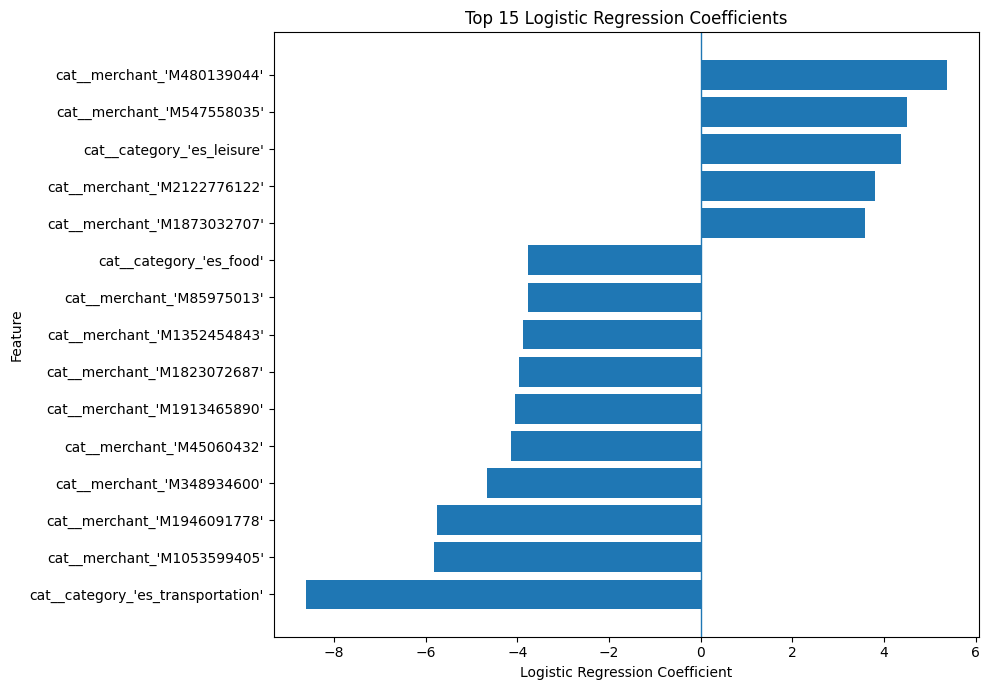

In [164]:
top_features = (
    feature_importance
    .head(15)
    .sort_values('coefficient')
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['feature'],
    top_features['coefficient']
)
plt.axvline(0, linewidth=1)
plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.title('Top 15 Logistic Regression Coefficients')
plt.tight_layout()
plt.show()

### Interpretation of Logistic Regression Coefficients

The coefficient analysis shows that transaction category and merchant identity are influential predictors in the Logistic Regression model. The `es_transportation` category has the strongest negative coefficient, while `es_leisure` has a strong positive coefficient. Several merchant identifiers also have large positive and negative coefficients, suggesting that the model captures merchant-specific patterns in the BankSim synthetic dataset.

Positive coefficients increase the model's estimated fraud odds, while negative coefficients decrease them, holding other features constant. These are statistical associations rather than causal relationships. Since the dataset is synthetic, these patterns should not be assumed to represent real-world banking behavior.

## Final Model Evaluation

Logistic Regression was selected based on its validation performance. The decision threshold was selected on the validation set to maximize precision subject to a minimum target fraud recall of 80%.

### Chronological Test Results

| Metric | Result |
|---|---:|
| Validation Average Precision | 0.9057 |
| Selected decision threshold | 0.9857 |
| Test Average Precision | 0.9160 |
| Test fraud precision | 86.63% |
| Test fraud recall | 79.81% |
| Test true positives | 862 |
| Test false positives | 133 |
| Test false negatives | 218 |
| Test true negatives | 98,904 |

The model correctly identified 862 of the 1,080 fraudulent transactions in the chronological test period. It also flagged 133 legitimate transactions as potentially fraudulent and missed 218 fraudulent transactions.

The test recall is slightly below the 80% validation target. This illustrates that performance on a later time period can differ from validation performance.

Average Precision is reported alongside precision and recall because accuracy alone can be misleading when the target classes are highly imbalanced.

These results represent one chronological evaluation on synthetic data, not a guarantee of performance on real banking transactions.

In [160]:
import joblib
from sklearn.pipeline import Pipeline

fraud_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lr_model)
])

joblib.dump(
    {
        "pipeline": fraud_pipeline,
        "threshold": best_threshold,
        "feature_columns": feature_cols
    },
    "fraud_detection_pipeline.joblib"
)

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [161]:
import joblib

saved_model = joblib.load("fraud_detection_pipeline.joblib")

loaded_pipeline = saved_model["pipeline"]
threshold = saved_model["threshold"]

sample = X_test.iloc[[0]]

probability = loaded_pipeline.predict_proba(sample)[0, 1]
prediction = int(probability >= threshold)

print("Fraud probability:", round(probability, 4))
print("Selected threshold:", round(threshold, 4))
print("Prediction:", "Fraud" if prediction == 1 else "Legitimate")

Fraud probability: 0.0
Selected threshold: 0.9857
Prediction: Legitimate


In [163]:
print("Exact fraud probability:", loaded_pipeline.predict_proba(sample)[0, 1])
print("Actual label:", int(y_test.iloc[0]))

Exact fraud probability: 3.087535162028144e-07
Actual label: 0


## Conclusion and Limitations

This project explored financial transaction fraud detection using the BankSim synthetic dataset. Exploratory analysis revealed substantial class imbalance and differences in observed fraud rates across transaction categories and merchants.

Logistic Regression achieved the strongest validation Average Precision among the compared models. Customer-history features improved validation Average Precision from 0.9003 to 0.9057 in the recorded ablation experiment. The selected decision threshold provided a practical way to trade off fraud detection against false alarms.

### Limitations
- BankSim contains synthetic transactions, so the learned patterns may not generalize to real financial institutions.
- Evaluation uses a single chronological split and does not establish robustness across different time periods.
- Merchant and category associations are predictive relationships, not causal explanations.
- The selected threshold may require recalibration when transaction patterns or operational requirements change.
- The saved model requires correctly constructed customer-history features at prediction time.

### Future Work
Future improvements include testing on additional time periods, evaluating feature importance more rigorously, adding automated tests, and developing a FastAPI application for transaction-risk predictions.

Overall, this project demonstrates an end-to-end machine learning workflow covering exploratory analysis, feature engineering, model comparison, threshold selection, evaluation, explainability, and deployment preparation.